# ReMedFiLM — Complete Research Notebook

**ReMedFiLM (FULL RA-MedFiLM-BARR)** — task-conditioned global-to-regional medical
image segmentation with risk-averse refinement.

| | |
|---|---|
| Repository | `D:\Softfors\jup` |
| Model | G (GlobalMedFiLM) + B_phi (Benefit Router) + R_psi (Regional Refiner) + S_omega (Post-Safety Gate) |
| Parameters | 4,837,420 (backbone 3,523,001) |
| Development population | TRAIN 5,832 · VAL 808 · ROUTER_DEVELOPMENT 4,957 · ROUTER_HOLDOUT 875 |
| Execution mode | **ANALYSIS ONLY** — no training, no new inference, no TEST access |

> **This notebook does not train anything.** It reads persisted artifacts and
> rebuilds the tables and figures of the research record. Every cell is guarded;
> see Section 00.

## Notebook map

| § | Section | Primary evidence |
|---|---|---|
| 00 | Research environment and execution guard | interpreter, GPU, guard |
| 01 | Research overview | methodology figure |
| 02 | Dataset analysis | manifests, VAL808 |
| 03 | Full ReMedFiLM architecture | parameter contract |
| 04 | Historical training run inventory | 82 history files |
| 05 | Epoch-by-epoch training improvements | T1–T8 |
| 06 | Historical baseline comparison | six-model VAL808 |
| 07 | ReMedFiLM internal evaluation | saved masks |
| 08 | Class and subclass evaluation | KUB taxonomy |
| 09 | Semantic segmentation gallery | saved masks |
| 10 | External retrospective evaluation | 884 cases |
| 11 | Component progression | Phase 28 / C2 |
| 12 | Complete ablation study | 13 arms |
| 13 | Error propagation and routing | VAL808 branches |
| 14 | Robustness and interpretability | Phase 35/36 |
| 15 | Computational efficiency | Phase 34 |
| 16 | Historical TEST evidence | Phase 39 record only |
| 17 | Conclusions and missing evidence | — |

---
# 00 — Research environment and execution guard

Every subsequent cell calls `G.require()` first. The guard is an actual
`sys.addaudithook` plus runtime patches, not a boolean flag:

* blocks `subprocess` / `os.system` / `os.exec*` launches,
* blocks writes outside `full_doc_report/`,
* blocks any read of the protected TEST manifest,
* makes `torch.optim.*` constructors raise,
* makes `Module.train(True)` raise.

In [1]:
import sys, os, json, csv, hashlib, platform, builtins
from pathlib import Path
from datetime import datetime

ANALYSIS_ONLY = True
REPO = Path(r"D:\Softfors\jup")
REPORT = REPO / "full_doc_report"
TABLES = REPORT / "tables"
FIGURES = REPORT / "figures"

class AnalysisOnlyViolation(RuntimeError):
    """Raised when a cell attempts a non-analysis operation."""

PROTECTED_READS = {
    (REPO / "manifests/phase4_v3/test.csv").resolve(),
}
BLOCKED_EVENTS = {"subprocess.Popen", "os.system", "os.exec", "os.spawn",
                  "os.posix_spawn", "os.startfile", "pty.spawn"}
_WRITE_FLAGS = os.O_WRONLY | os.O_RDWR | os.O_APPEND | os.O_CREAT | os.O_TRUNC

# Constants are bound as default arguments so the hook stays valid during
# interpreter teardown, when module globals have already been cleared.
def _audit(event, args, _blocked=frozenset(BLOCKED_EVENTS),
           _protected=frozenset(PROTECTED_READS),
           _report=str(REPORT), _flags=_WRITE_FLAGS, _path=Path):
    if event in _blocked:
        raise AnalysisOnlyViolation(f"blocked process launch: {event}")
    if event == "open":
        path, mode, flags = args
        try:
            p = _path(path).resolve()
        except Exception:
            return
        if str(p) in {str(x) for x in _protected}:
            raise AnalysisOnlyViolation(f"protected TEST manifest access: {p}")
        writing = False
        if isinstance(mode, str):
            writing = any(c in mode for c in "wax+")
        if isinstance(flags, int) and flags & _flags:
            writing = True
        if writing and _report not in str(p.parent) and str(p) != _report:
            raise AnalysisOnlyViolation(f"write outside full_doc_report: {p}")

sys.addaudithook(_audit)

# torch optimisers must never be constructible in this notebook
try:
    import torch
    import torch.optim as _optim
    def _no_optimiser(*a, **k):
        raise AnalysisOnlyViolation("optimiser construction is forbidden (analysis only)")
    for _n in ("SGD", "Adam", "AdamW", "RMSprop", "Adagrad"):
        if hasattr(_optim, _n):
            setattr(_optim, _n, _no_optimiser)
    _orig_train = torch.nn.Module.train
    def _guarded_train(self, mode=True):
        if mode:
            raise AnalysisOnlyViolation("Module.train(True) is forbidden (analysis only)")
        return _orig_train(self, False)
    torch.nn.Module.train = _guarded_train
except ImportError:
    torch = None

class Guard:
    """Accessor handed to every cell."""
    def require(self):
        if not ANALYSIS_ONLY:
            raise AnalysisOnlyViolation("ANALYSIS_ONLY was disabled")
        return True
    def blocked(self, what):
        raise AnalysisOnlyViolation(what)

G = Guard()
G.require()
print("ANALYSIS_ONLY guard active")

ANALYSIS_ONLY guard active


In [2]:
G.require()
# Negative controls: the guard must actually refuse these operations.
# If any of them succeeds, enforcement is broken and the notebook is invalid.
checks = []

try:
    torch.optim.Adam([])
    checks.append(("optimiser construction", "NOT BLOCKED"))
except AnalysisOnlyViolation as e:
    checks.append(("optimiser construction", "blocked"))

try:
    torch.optim.AdamW([])
    checks.append(("AdamW construction", "NOT BLOCKED"))
except AnalysisOnlyViolation as e:
    checks.append(("AdamW construction", "blocked"))

try:
    (REPO / "manifests/phase4_v3/test.csv").open("rb").read(1)
    checks.append(("TEST manifest read", "NOT BLOCKED"))
except AnalysisOnlyViolation:
    checks.append(("TEST manifest read", "blocked"))
except FileNotFoundError:
    checks.append(("TEST manifest read", "blocked (file absent)"))

try:
    (REPO / "reports" / "_guard_probe.txt").open("w").write("x")
    checks.append(("write outside report dir", "NOT BLOCKED"))
except AnalysisOnlyViolation:
    checks.append(("write outside report dir", "blocked"))

for name, verdict in checks:
    print(f"  {name:28s}: {verdict}")

assert all(v.startswith("blocked") for _, v in checks), "GUARD FAILED — do not trust this notebook"
print()
print("All negative controls blocked. Analysis-only enforcement verified.")

  optimiser construction      : blocked
  AdamW construction          : blocked
  TEST manifest read          : blocked
  write outside report dir    : blocked

All negative controls blocked. Analysis-only enforcement verified.


In [3]:
G.require()
import importlib.metadata as md

def _v(name):
    try:
        return md.version(name)
    except Exception:
        return "not installed"

env = {
    "python": sys.version.split()[0],
    "executable": sys.executable,
    "prefix": sys.prefix,
    "platform": platform.platform(),
    "processor": platform.processor(),
    "torch": _v("torch"),
    "numpy": _v("numpy"),
    "pandas": _v("pandas"),
    "matplotlib": _v("matplotlib"),
    "scipy": _v("scipy"),
    "nbformat": _v("nbformat"),
    "nbclient": _v("nbclient"),
}
if torch is not None:
    env["cuda_available"] = torch.cuda.is_available()
    env["cuda_version"] = torch.version.cuda
    if torch.cuda.is_available():
        env["gpu"] = torch.cuda.get_device_name(0)
        env["gpu_memory_gib"] = round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3, 2)
        env["gpu_capability"] = torch.cuda.get_device_capability(0)
for k, v in env.items():
    print(f"{k:16s}: {v}")

python          : 3.11.9
executable      : D:\Softfors\jup\.venv\Scripts\python.exe
prefix          : D:\Softfors\jup\.venv
platform        : Windows-10-10.0.26200-SP0
processor       : AMD64 Family 25 Model 33 Stepping 2, AuthenticAMD
torch           : 2.6.0+cu124
numpy           : 2.4.6
pandas          : 3.0.5
matplotlib      : 3.11.2
scipy           : 1.17.1
nbformat        : 5.11.1
nbclient        : 0.11.0
cuda_available  : True
cuda_version    : 12.4
gpu             : NVIDIA GeForce RTX 3060 Ti
gpu_memory_gib  : 8.0
gpu_capability  : (8, 6)


In [4]:
G.require()
# Determinism: analysis only, so we pin plotting/statistics seeds rather than
# any training RNG. Documented so a re-run reproduces identical figures.
import random
import numpy as np
ANALYSIS_SEED = 20261027
random.seed(ANALYSIS_SEED)
np.random.seed(ANALYSIS_SEED)
print("analysis seed:", ANALYSIS_SEED)
print("read-only root:", REPORT)

analysis seed: 20261027
read-only root: D:\Softfors\jup\full_doc_report


In [5]:
G.require()
# Original notebook source registry (from the preservation manifest).
import pandas as pd

pres = json.loads((REPORT / "NOTEBOOK_PRESERVATION_MANIFEST.json").read_text(encoding="utf-8"))
print("preserved source notebooks:", pres["n_source_notebooks"])
print("byte-identical copies     :", pres["n_verified_byte_identical"])
inv = pd.read_csv(REPORT / "NOTEBOOK_INVENTORY.csv")
print("inventory rows            :", len(inv))
print("genuine sources           :", (inv.merge_status == "SOURCE_OF_TRUTH").sum())
display_cols = ["original_path", "phase_or_experiment", "code_cells", "has_outputs",
                "side_effects", "execution_eligibility"]
inv[inv.merge_status == "SOURCE_OF_TRUTH"][display_cols].head(12)

preserved source notebooks: 140
byte-identical copies     : 140
inventory rows            : 418
genuine sources           : 140


,original_path,phase_or_experiment,code_cells,has_outputs,side_effects,execution_eligibility
0,.workbuddy-ai/phase21_notebook_ORIGINAL_backup...,PHASE_21,37,YES,INFERENCE(2)|TEST_PATH_REFERENCE,ANALYSIS_ELIGIBLE
1,.workbuddy-ai/phase21_notebook_REPAIRED_backup...,PHASE_21,37,YES,INFERENCE(2)|TEST_PATH_REFERENCE,ANALYSIS_ELIGIBLE
280,notebooks/00_project_initialization.ipynb,UNMAPPED,1,YES,NONE_DETECTED,ANALYSIS_ELIGIBLE
281,notebooks/00_project_visual_index.ipynb,PHASE_15,1,YES,INFERENCE(1),ANALYSIS_ELIGIBLE
282,notebooks/01_environment_and_data_audit.ipynb,UNMAPPED,1,YES,NONE_DETECTED,ANALYSIS_ELIGIBLE
283,notebooks/01_trained_model_results_visual_scor...,PHASE_10,4,YES,INFERENCE(1),ANALYSIS_ELIGIBLE
284,notebooks/02_dataset_discovery.ipynb,UNMAPPED,1,YES,NONE_DETECTED,ANALYSIS_ELIGIBLE
285,notebooks/03_kub_forensic_audit.ipynb,UNMAPPED,0,NO,NONE_DETECTED,ANALYSIS_ELIGIBLE
286,notebooks/03_leakage_and_split_audit.ipynb,UNMAPPED,2,YES,NONE_DETECTED,ANALYSIS_ELIGIBLE
287,notebooks/04_kub_characterization.ipynb,UNMAPPED,4,YES,NONE_DETECTED,ANALYSIS_ELIGIBLE


---
# 01 — Research overview

**ReMedFiLM** is not a single network. It is an assembly:

| Symbol | Component | Role |
|---|---|---|
| G | GlobalMedFiLM | task-conditioned FiLM backbone, one shared foreground head |
| B_phi | Benefit Router | scores each ROI candidate, selects the top budget fraction |
| R_psi | Regional Refiner | re-segments selected ROIs at higher effective resolution |
| S_omega | Post-Safety Gate | accepts or vetoes each refined proposal |

Three inference outcomes: **skip** (keep global), **refine + accept**, **refine + reject**
(revert to global). GlobalMedFiLM alone is the backbone and an ablation comparator —
it is *not* ReMedFiLM.

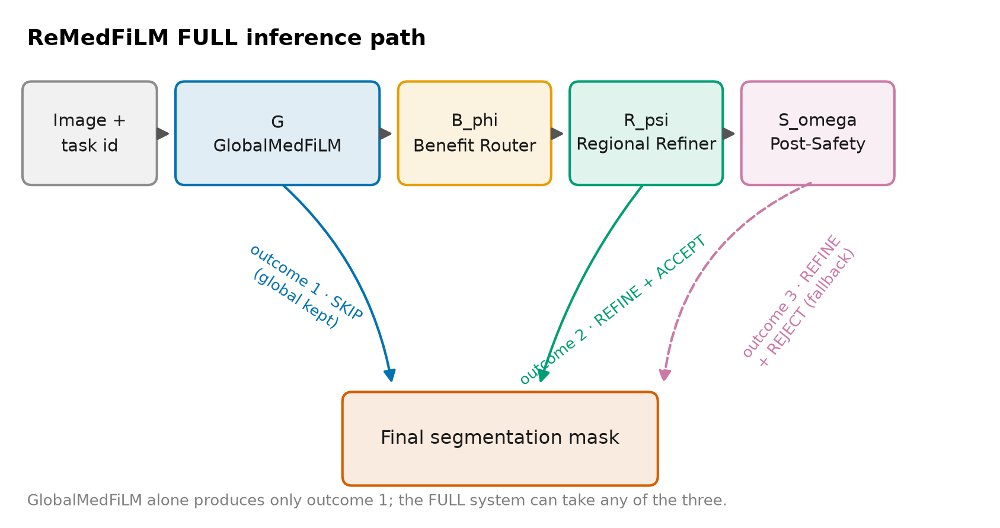

In [6]:
G.require()
from IPython.display import Image, display
display(Image(filename=str(FIGURES / "architecture/A03_remedfilm_inference_path.png"), width=760))

In [7]:
G.require()
# Exact identities used throughout this notebook.
IDENTITIES = pd.DataFrame([
    {"name": "GlobalMedFiLM (G)", "role": "BACKBONE", "params": 3523001,
     "gmacs": 31.5517, "checkpoint": "checkpoints/phase21_global_medfilm_fourdomain_seed42_clean_v3/best.pt"},
    {"name": "R_psi (Regional Refiner)", "role": "COMPONENT", "params": 1276401,
     "gmacs": None, "checkpoint": "experiments/phase25a_barr_regional_refiner_v1_1/final_refit/final.pt"},
    {"name": "B_phi (Benefit Router)", "role": "COMPONENT", "params": 36801,
     "gmacs": None, "checkpoint": "experiments/phase25d_barr_benefit_router_v1_2_1_seed42/final/"},
    {"name": "S_omega (Post-Safety Gate)", "role": "COMPONENT", "params": 1217,
     "gmacs": None, "checkpoint": "experiments/phase25f_barr_post_safety_v1_0_seed42/final/"},
    {"name": "ReMedFiLM (FULL)", "role": "PROPOSED", "params": 4837420,
     "gmacs": 32.4379, "checkpoint": "bundle of the four components above"},
])
print("Total resident parameters:", IDENTITIES.params.sum())
IDENTITIES

Total resident parameters: 9674840


,name,role,params,gmacs,checkpoint
0,GlobalMedFiLM (G),BACKBONE,3523001,31.5517,checkpoints/phase21_global_medfilm_fourdomain_...
1,R_psi (Regional Refiner),COMPONENT,1276401,NaN,experiments/phase25a_barr_regional_refiner_v1_...
2,B_phi (Benefit Router),COMPONENT,36801,NaN,experiments/phase25d_barr_benefit_router_v1_2_...
3,S_omega (Post-Safety Gate),COMPONENT,1217,NaN,experiments/phase25f_barr_post_safety_v1_0_see...
4,ReMedFiLM (FULL),PROPOSED,4837420,32.4379,bundle of the four components above


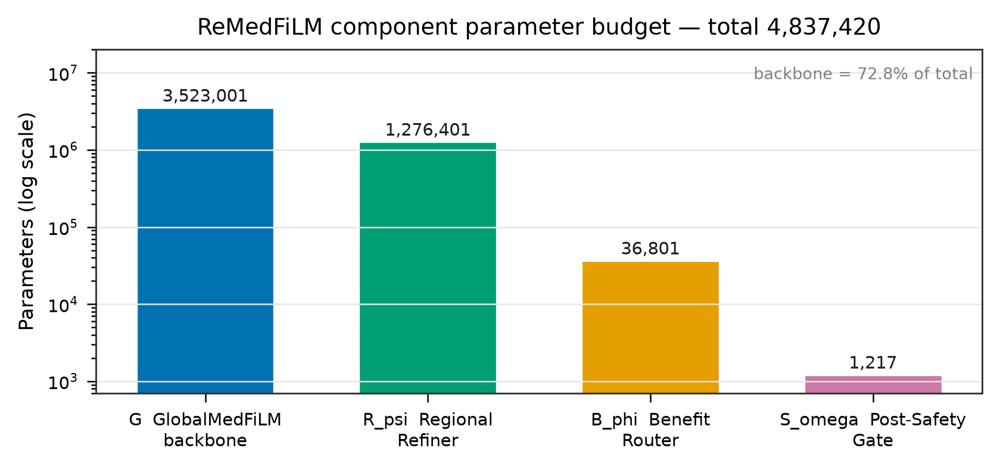

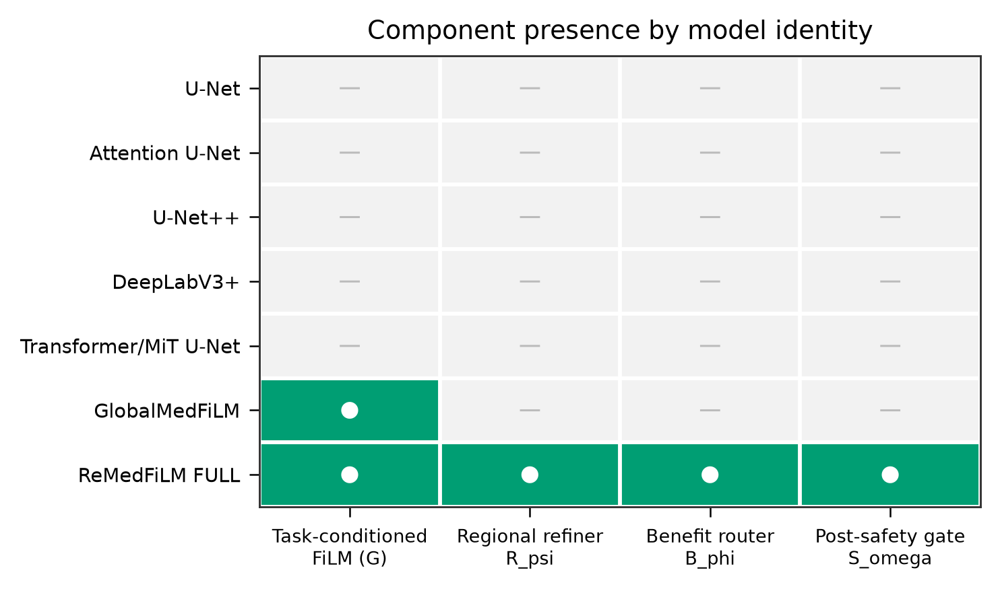

In [8]:
G.require()
display(Image(filename=str(FIGURES / "architecture/A01_component_parameter_budget.png"), width=720))
display(Image(filename=str(FIGURES / "architecture/A02_component_presence_matrix.png"), width=520))

---
# 02 — Dataset analysis

Four binary foreground/background segmentation domains. They are **separate
tasks**, not four output channels of one network.

| Domain | Anatomy | Reference standard |
|---|---|---|
| ISIC 2018 | dermoscopy skin lesion | expert segmentation mask (CC0) |
| BUSI-WHU | breast ultrasound lesion | expert annotation (CC BY 4.0) |
| Kvasir-SEG | GI polyp | expert mask (research use) |
| KUB-StoneX | kidney/ureter/bladder stone | expert mask (CC BY 4.0) |

Grouping caveats are reported explicitly: KUB mixes full-field images with ROI
instance patches, and BUSI/KUB carry patient identifiers that make images
non-independent.

In [9]:
G.require()
comp = pd.read_csv(TABLES / "REMEDFILM_DATASET_COMPOSITION.csv")
print("TRAIN+VAL =", int(comp.loc[comp.domain == "TOTAL", "total"].iloc[0]))
comp

TRAIN+VAL = 6640


,domain,train,val,total
0,ISIC,2556,357,2913
1,BUSI,602,84,686
2,KVASIR,696,87,783
3,KUB,1978,280,2258
4,TOTAL,5832,808,6640


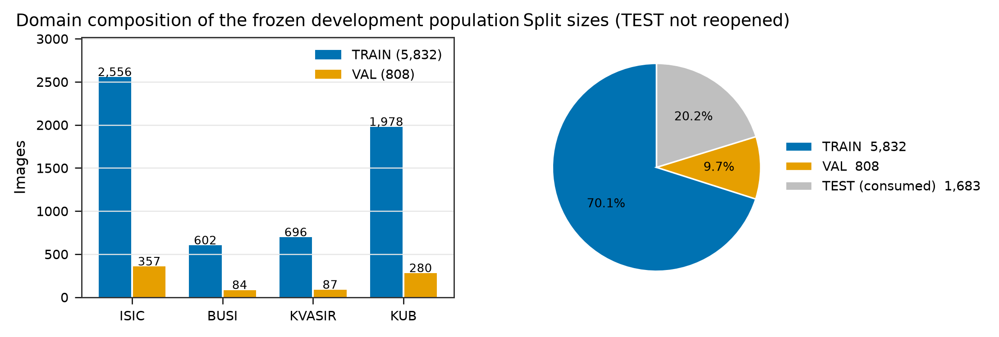

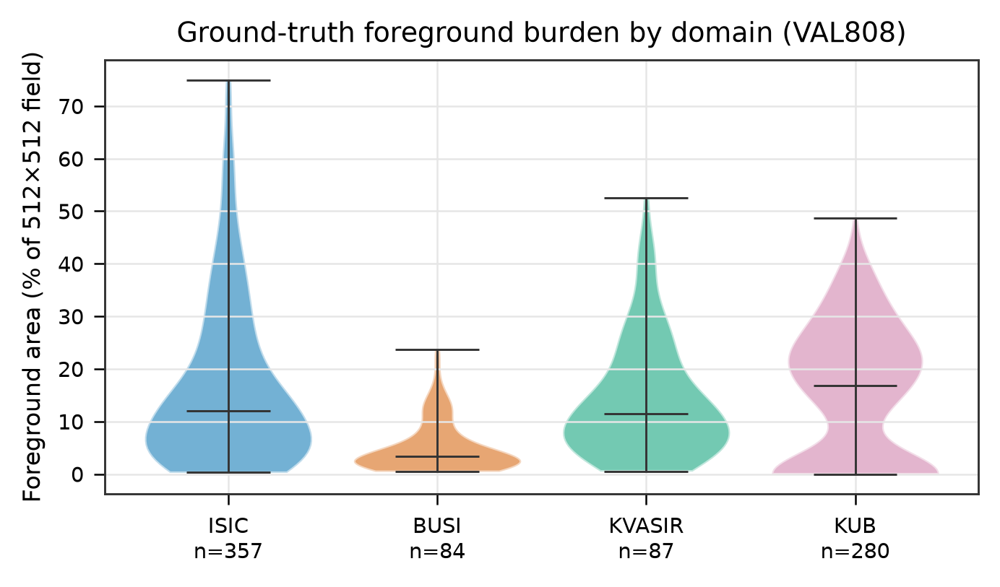

In [10]:
G.require()
display(Image(filename=str(FIGURES / "datasets/D01_domain_and_split_composition.png"), width=760))
display(Image(filename=str(FIGURES / "datasets/D02_foreground_area_distribution.png"), width=560))

KUB manifest rows        : 2258


  full-field images      : 873
  ROI instance patches   : 1385
Distinct source images   : 893

NOTE: pooled image counts overstate independent KUB cases; the 808 VAL
population is the analysis unit used for every metric in this notebook.


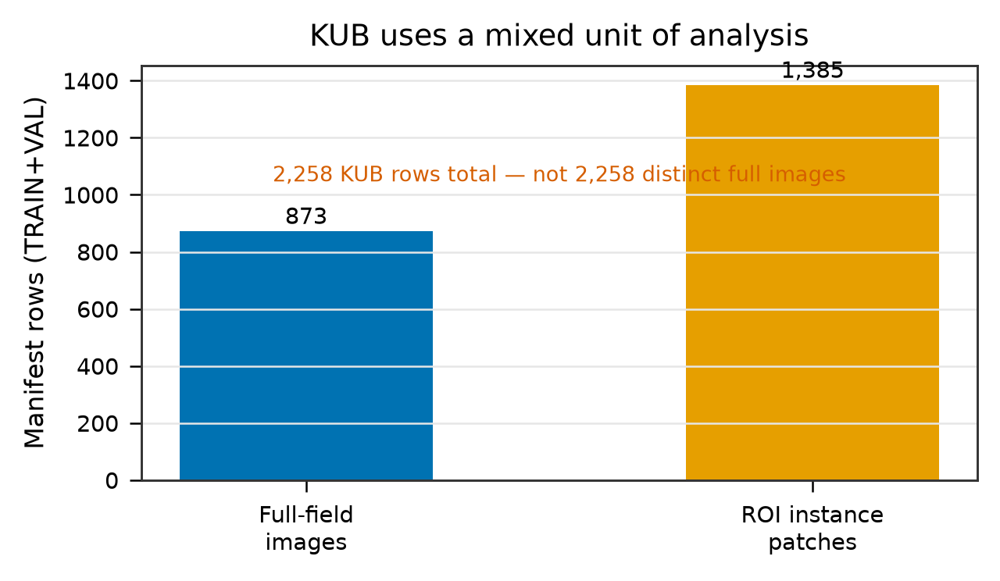

In [11]:
G.require()
# KUB unit-of-analysis disclosure: 873 full-field images + 1,385 ROI patches.
import csv as _csv
rows = []
for f in ("train.csv", "val.csv"):
    with (REPO / "manifests/phase4_v3" / f).open(encoding="utf-8", newline="") as fh:
        rows.extend(list(_csv.DictReader(fh)))
kub = [r for r in rows if r["dataset"] == "KUB"]
roi = sum(1 for r in kub if Path(r["image_path"]).parent.name == "ROI")
print(f"KUB manifest rows        : {len(kub)}")
print(f"  full-field images      : {len(kub) - roi}")
print(f"  ROI instance patches   : {roi}")
print("Distinct source images   :", len({Path(r['image_path']).stem.split('_stone_obj')[0] for r in kub}))
print()
print("NOTE: pooled image counts overstate independent KUB cases; the 808 VAL")
print("population is the analysis unit used for every metric in this notebook.")
display(Image(filename=str(FIGURES / "datasets/D03_kub_unit_of_analysis.png"), width=480))

---
# 03 — Full ReMedFiLM architecture

Parameter counts are read from the frozen contracts, not recomputed from scratch.
Freezing a component never reduces the *total* parameter count — the matched-arm
invariant of the C1 design.

In [12]:
G.require()
contract = json.loads((REPO / "reports/audits/phase34_parameter_count_contract.json").read_text(encoding="utf-8"))
print(json.dumps(contract, indent=2)[:1200])

{
  "artifact": "phase34_parameter_count_contract",
  "phase": 34,
  "section": "\u00a7O",
  "method": "RA-MedFiLM-BARR",
  "revision": "ra_medfilm_barr_phase34_efficiency_profiling_v1_0",
  "reported_quantities": [
    "total_parameter_count",
    "trainable_parameter_count",
    "non_trainable_parameter_count",
    "parameter_bytes_at_canonical_dtype",
    "checkpoint_file_bytes"
  ],
  "parameter_bytes_equals_checkpoint_file_bytes": false,
  "canonical_dtype_for_parameter_bytes": "float32",
  "parameter_bytes_convention": "numel * 4 bytes at float32",
  "conditional_system_distinction": {
    "TOTAL_RESIDENT_PARAMETERS": 4837420,
    "PARAMETERS_ACTIVE_ON_A_GIVEN_PATH": "path-dependent subset"
  },
  "conditional_execution_reduces_installed_parameter_count": false,
  "historical_parameter_counts": {
    "G": 3523001,
    "R_psi": 1276401,
    "B_phi": 36801,
    "S_omega": 1217,
    "sum_total_resident": 4837420
  },
  "generated_utc": "2026-10-04T09:50:07+00:00",
  "all_pass": true

In [13]:
G.require()
p21 = json.loads((REPO / "reports/audits/phase21_global_medfilm_architecture_binding.json").read_text(encoding="utf-8"))
print(json.dumps(p21, indent=2)[:1400])

{
  "artifact": "phase21_global_medfilm_architecture_binding",
  "phase": 21,
  "generated_utc": "2026-09-28T11:26:12.717649+00:00",
  "frozen_before_training": true,
  "training_performed_at_binding_time": false,
  "experiment_id": "phase21_global_medfilm_fourdomain_seed42_clean_v3",
  "architecture_id": "global_medfilm_shared_residual_unet_film5_no_se_no_deep_supervision_v1",
  "architecture_family": "GLOBAL_MEDFILM_TASK_CONDITIONED_SHARED_SEGMENTATION",
  "is_final_ra_medfilm_seg_plus_plus": false,
  "is_global_reference_only": true,
  "model_class": "src.models.film.global_medfilm.GlobalMedFiLM",
  "model_file": "src/models/film/global_medfilm.py",
  "model_file_sha256": "a04ff3e61b4d900ff47c2f390da4a999e73bd6047b28a19e41b05115e431d11f",
  "model_package_init_sha256": "3df73eaa3439429137bd09ea8c53f73baa75edcdc1acf57a3c57160da2ebeca7",
  "factory_file": "src/models/factory.py",
  "factory_file_sha256": "f97f97a5632675ae54e4c42a629d06d1b5e265f73c85ba6d0a2077b9147afdde",
  "measured_p

In [14]:
G.require()
# Component arithmetic must close exactly.
parts = {"G": 3523001, "R_psi": 1276401, "B_phi": 36801, "S_omega": 1217}
total = sum(parts.values())
print("component sum :", total)
print("contract total:", 4837420)
assert total == 4837420, "component sum does not match the frozen contract"
print("OK — the four components account for every resident parameter")
print()
print("backbone share: {:.2%}".format(parts["G"] / total))
print("adapter share : {:.2%}".format((total - parts["G"]) / total))

component sum : 4837420
contract total: 4837420
OK — the four components account for every resident parameter

backbone share: 72.83%
adapter share : 27.17%


---
# 04 — Historical training run inventory

82 per-epoch `history.csv` files were recovered across every experiment
directory. `best_epoch_source` states whether the selected epoch was **recorded**
by the trainer or **derived** by this notebook's analysis, so the two are never
conflated.

In [15]:
G.require()
reg = pd.read_csv(TABLES / "TRAINING_RUN_REGISTRY.csv")
print("runs:", len(reg))
print(reg.evidence_status.value_counts().to_string())
print()
print(reg.best_epoch_source.value_counts().to_string())

runs: 82
evidence_status
GENUINE_HISTORICAL_TRAINING              68
GENUINE_HISTORY_BEST_EPOCH_UNRESOLVED    14

best_epoch_source
RECORDED_FLAG                       37
RECORDED_CLOSURE                    19
NOT_RECORDED                        14
DERIVED_ARGMAX                       7
NOT_APPLICABLE_FIXED_EPOCH_REFIT     4
RECORDED_EVENT                       1


In [16]:
G.require()
core_models = ["GlobalMedFiLM (G)", "U-Net", "Attention U-Net", "U-Net++", "DeepLabV3+",
               "Transformer/MiT-style U-Net", "R_psi (Regional Refiner)",
               "B_phi (Benefit Router)", "S_omega (Post-Safety Gate)",
               "F1 (Ablation Variant)"]
show = ["run_id", "model", "seed", "epochs_completed", "best_epoch",
        "best_epoch_source", "evidence_status"]
reg[reg.model.isin(core_models)][show].head(25)

,run_id,model,seed,epochs_completed,best_epoch,best_epoch_source,evidence_status
16,phase20_shared_unetpp_fourdomain_seed42_clean_v3,U-Net++,42,70,55,RECORDED_CLOSURE,GENUINE_HISTORICAL_TRAINING
17,phase20b_shared_attention_unet_fourdomain_seed...,Attention U-Net,42,79,64,RECORDED_CLOSURE,GENUINE_HISTORICAL_TRAINING
18,phase20b_shared_deeplabv3plus_fourdomain_seed4...,DeepLabV3+,42,72,57,RECORDED_CLOSURE,GENUINE_HISTORICAL_TRAINING
19,phase20b_shared_transformer_mit_unet_fourdomai...,Transformer/MiT-style U-Net,42,89,74,RECORDED_CLOSURE,GENUINE_HISTORICAL_TRAINING
20,phase20b_shared_unet_fourdomain_seed42_clean_v3,U-Net,42,89,74,RECORDED_CLOSURE,GENUINE_HISTORICAL_TRAINING
21,phase21_global_medfilm_fourdomain_seed42_clean_v3,GlobalMedFiLM (G),42,81,66,RECORDED_CLOSURE,GENUINE_HISTORICAL_TRAINING
22,phase25a_barr_regional_refiner_v1_1__final_refit,R_psi (Regional Refiner),UNKNOWN,27,NOT_APPLICABLE,NOT_APPLICABLE_FIXED_EPOCH_REFIT,GENUINE_HISTORICAL_TRAINING
23,phase25a_barr_regional_refiner_v1_1__fold0,R_psi (Regional Refiner),UNKNOWN,50,34,RECORDED_CLOSURE,GENUINE_HISTORICAL_TRAINING
24,phase25a_barr_regional_refiner_v1_1__fold1,R_psi (Regional Refiner),UNKNOWN,43,27,RECORDED_CLOSURE,GENUINE_HISTORICAL_TRAINING
25,phase25a_barr_regional_refiner_v1_1__fold2,R_psi (Regional Refiner),UNKNOWN,34,18,RECORDED_CLOSURE,GENUINE_HISTORICAL_TRAINING


In [17]:
G.require()
# Runs whose selection epoch genuinely was not logged.
missing = reg[reg.best_epoch == "NOT_RECORDED"][["run_id", "model", "epochs_completed"]]
print(f"runs without a per-epoch selection record: {len(missing)}")
print("These are KUB ROI-localiser diagnostics and fixed-epoch component refits.")
missing

runs without a per-epoch selection record: 14
These are KUB ROI-localiser diagnostics and fixed-epoch component refits.


,run_id,model,epochs_completed
0,h3_kub_localizer_sigma_adaptive_sizeaware_seed...,KUB localizer (H3),69
8,phase13b_kub_localizer_r512_h128_sigmaeq075_ce...,KUB localizer (ROI proposal),88
9,phase13b_kub_localizer_r512_s3_centernetfocal_...,KUB localizer (ROI proposal),13
10,phase13b_kub_localizer_r512_s3_centernetfocal_...,KUB localizer (ROI proposal),3
11,phase13b_kub_localizer_r512_s3_centernetfocal_...,KUB localizer (ROI proposal),100
12,phase13b_kub_localizer_r512_s3_seed42,KUB localizer (ROI proposal),19
13,phase13b_kub_localizer_r512_s3_seed42_v2,KUB localizer (ROI proposal),24
14,phase13b_kub_localizer_r512_s3_seed42_v3,KUB localizer (ROI proposal),26
30,phase25d_barr_benefit_router_v1_2_1_seed42__final,B_phi (Benefit Router),80
41,phase25f_barr_post_safety_v1_0_seed42__final,S_omega (Post-Safety Gate),23


---
# 05 — Epoch-by-epoch training improvements

This is the section that cannot be reconstructed by guessing. All curves come
from `history.csv` files written by the trainers. Nothing is interpolated,
smoothed or invented; a metric that was never logged simply has no curve.

GlobalMedFiLM logged **per-domain validation Dice, IoU, precision and recall at
every epoch**, so the per-domain learning curves below are genuine observations.

In [18]:
G.require()
hist = pd.read_csv(TABLES / "REMEDFILM_EPOCH_HISTORY.csv")
print("long-form epoch records:", len(hist))
print("runs                   :", hist.run_id.nunique())
print("distinct metrics       :", hist.metric.nunique())
print()
print(hist.metric.value_counts().head(18).to_string())

long-form epoch records: 35764
runs                   : 82
distinct metrics       : 42

metric
learning_rate                     5094
epoch_seconds                     4739
train_loss                        2440
train_huber                       1786
val_loss                          1755
val_router_huber                  1571
train_bce                         1482
best_epoch_so_far                 1449
val_safety_bce                     803
peak_gpu_allocated                 640
peak_gpu_reserved                  640
val_localizer_tiny_recall90        626
val_localizer_overall_recall90     626
train_dice_loss                    614
val_refiner_loss                   583
val_macro_dice                     539
val_dice                           519
val_iou                            519


In [19]:
G.require()
g = hist[hist.run_id == "phase21_global_medfilm_fourdomain_seed42_clean_v3"]
piv = g.pivot_table(index="epoch", columns="metric", values="value")
print("GlobalMedFiLM epochs recorded:", len(piv))
piv[["train_loss", "val_loss", "val_macro_dice"]].head(8)

GlobalMedFiLM epochs recorded: 81


metric,train_loss,val_loss,val_macro_dice
epoch,,,
1,0.389364,0.290113,0.615488
2,0.299246,0.264576,0.638738
3,0.263231,0.244905,0.665535
4,0.245135,0.251465,0.686645
5,0.219440,0.214046,0.717838
6,0.204772,0.213325,0.728646
7,0.189258,0.209909,0.730743
8,0.181256,0.192939,0.757922


In [20]:
G.require()
# Recorded versus derived selection epochs for the backbone.
print("closure.json  best_epoch =", 66)
print("history argmax(val_macro_dice) =",
      int(piv["val_macro_dice"].idxmax()),
      "value =", round(float(piv["val_macro_dice"].max()), 8))
print("final epoch recorded =", int(piv.index.max()))
print("stop reason          = EARLY_STOPPING_PATIENCE (patience 15)")

closure.json  best_epoch = 66
history argmax(val_macro_dice) = 66 value = 0.83507913
final epoch recorded = 81
stop reason          = EARLY_STOPPING_PATIENCE (patience 15)


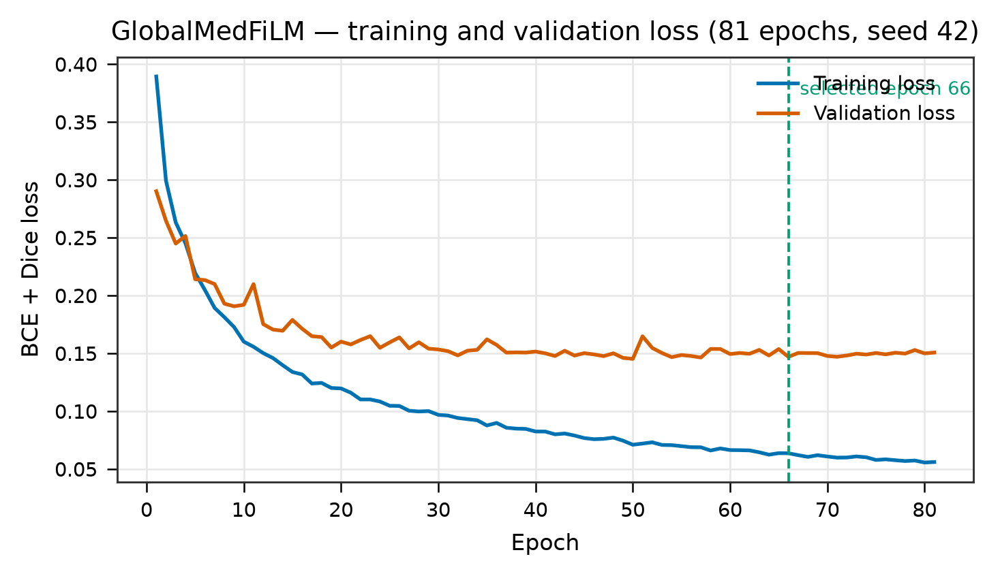

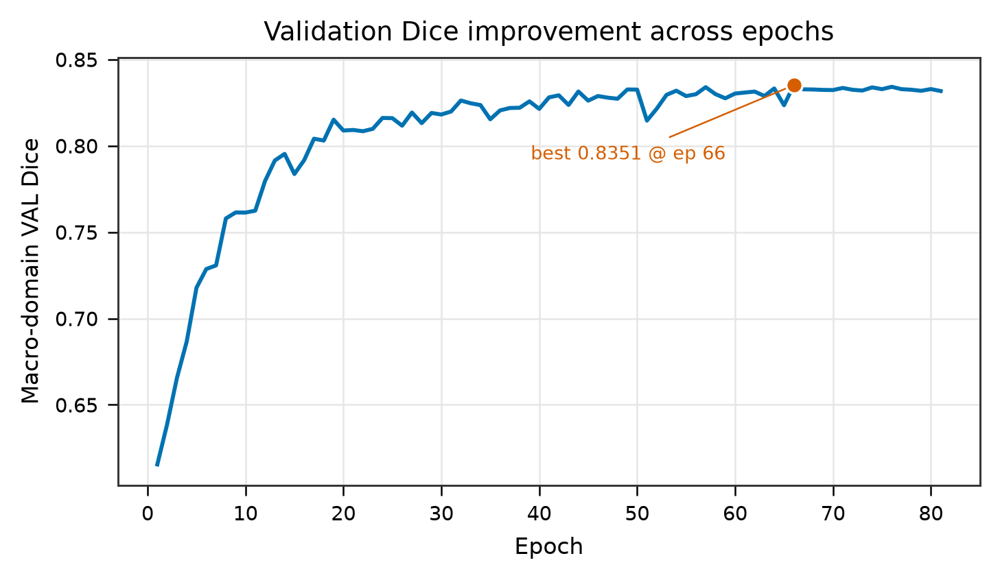

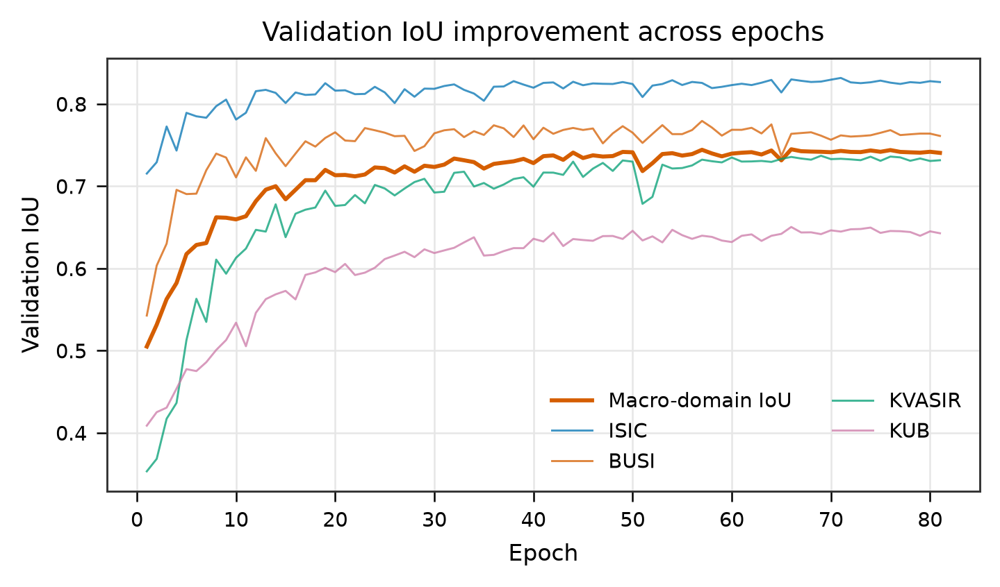

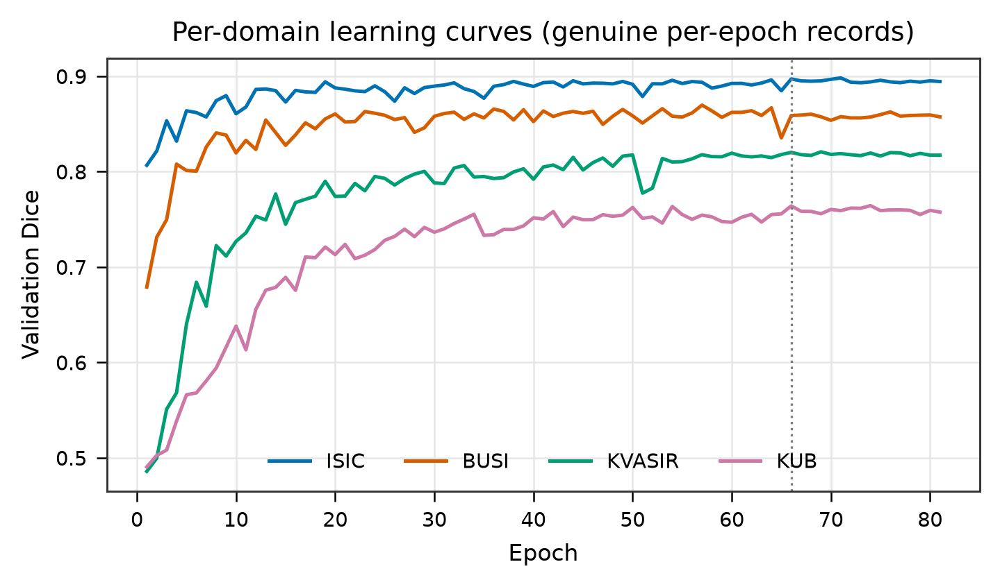

In [21]:
G.require()
for f in ["T1_train_val_loss", "T2_val_dice_across_epochs", "T3_val_iou_across_epochs",
          "T4_per_domain_learning_curves"]:
    display(Image(filename=str(FIGURES / f"training_epochs/{f}.png"), width=700))

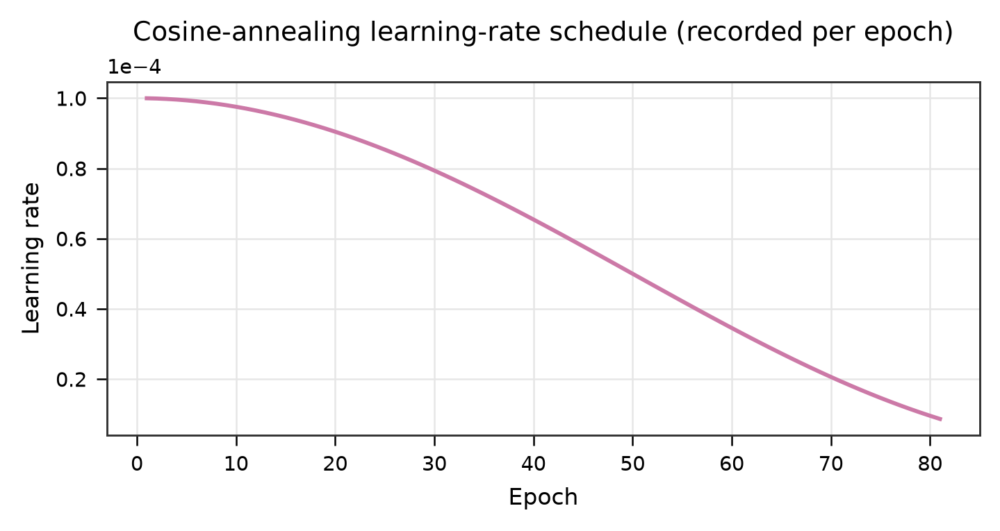

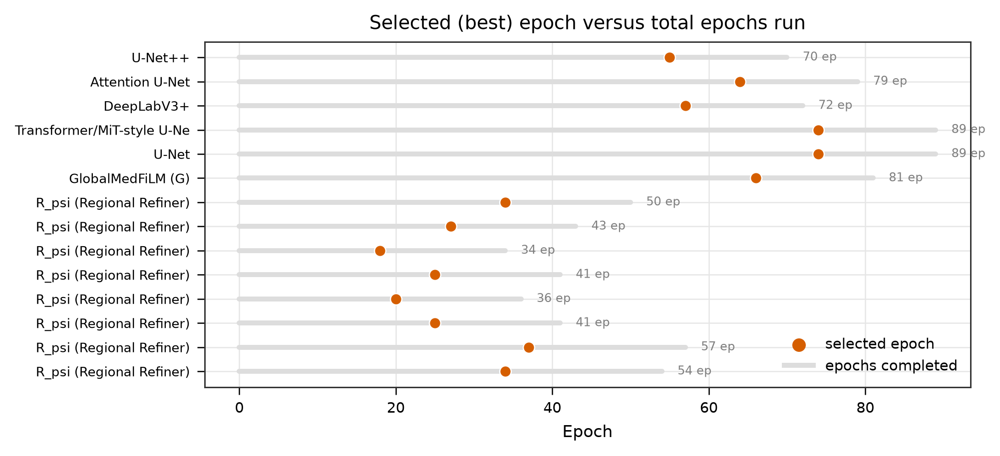

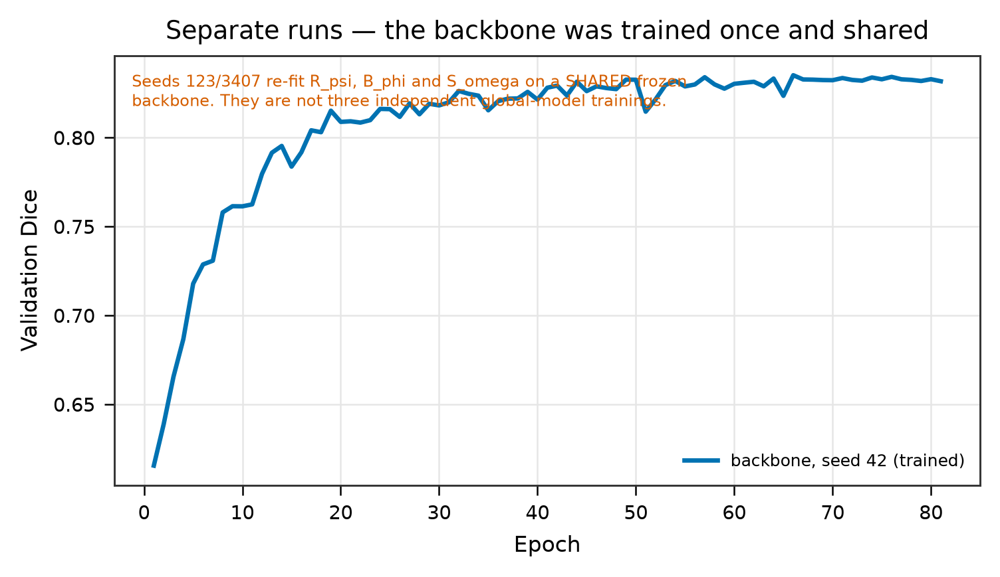

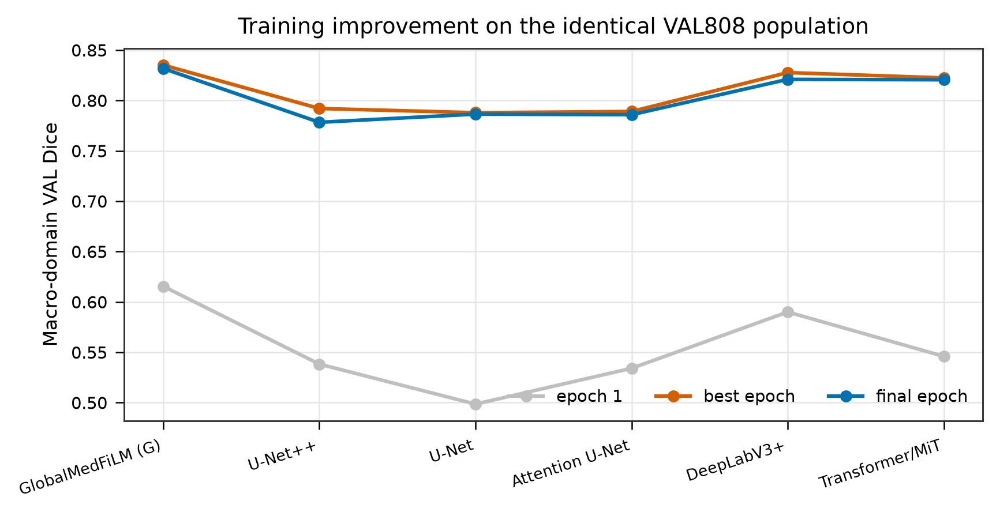

In [22]:
G.require()
for f in ["T5_learning_rate_schedule", "T6_best_epoch_selection",
          "T7_multiseed_histories", "T8_training_improvement_summary"]:
    display(Image(filename=str(FIGURES / f"training_epochs/{f}.png"), width=700))

In [23]:
G.require()
# Honest completeness statement per model family.
def coverage(run_prefix):
    sub = hist[hist.run_id.str.startswith(run_prefix)]
    if sub.empty:
        return "NOT_RECORDED"
    return ", ".join(sorted(sub.metric.unique())[:8])

rows = []
for label, prefix in [
    ("GlobalMedFiLM (G)", "phase21_global_medfilm"),
    ("U-Net++ (4-domain)", "phase20_shared_unetpp"),
    ("U-Net (4-domain)", "phase20b_shared_unet_"),
    ("Attention U-Net", "phase20b_shared_attention"),
    ("DeepLabV3+", "phase20b_shared_deeplab"),
    ("Transformer/MiT", "phase20b_shared_transformer"),
    ("R_psi refiner", "phase25a_barr_regional_refiner_v1_1__fold0"),
    ("B_phi router", "phase25d_barr_benefit_router_v1_2_1_seed42__fold0"),
    ("S_omega safety", "phase25f_barr_post_safety_v1_0_seed42__cv_fold0"),
]:
    rows.append({"model": label, "epoch_metrics_logged": coverage(prefix)})
import pandas as pd
pd.DataFrame(rows)

,model,epoch_metrics_logged
0,GlobalMedFiLM (G),"best_epoch_so_far, best_metric_so_far, epoch_s..."
1,U-Net++ (4-domain),"best_epoch_so_far, epoch_seconds, learning_rat..."
2,U-Net (4-domain),"best_epoch_so_far, epoch_seconds, learning_rat..."
3,Attention U-Net,"best_epoch_so_far, epoch_seconds, learning_rat..."
4,DeepLabV3+,"best_epoch_so_far, epoch_seconds, learning_rat..."
5,Transformer/MiT,"best_epoch_so_far, epoch_seconds, learning_rat..."
6,R_psi refiner,"best_epoch_so_far, epoch_seconds, learning_rat..."
7,B_phi router,"epoch_seconds, learning_rate, train_huber, val..."
8,S_omega safety,"epoch_seconds, learning_rate, train_bce, val_s..."


---
# 06 — Historical baseline comparison

Six models were trained under one shared protocol on the identical VAL808
population (Phase 20/20B/21). Phase 21 inherits 24/24 protocol fields, so the
comparison is descriptive but protocol-matched.

ReMedFiLM FULL is shown **separately** — it is a different assembly evaluated on
the same samples, not a seventh independent training run.

In [24]:
G.require()
comp = pd.read_csv(TABLES / "REMEDFILM_MODEL_COMPARISON.csv")
comp[["model", "role", "params", "macro_dice", "macro_iou",
      "dice_ISIC", "dice_BUSI", "dice_KVASIR", "dice_KUB"]].to_string(index=False)

'                      model                 role     params  macro_dice  macro_iou  dice_ISIC  dice_BUSI  dice_KVASIR  dice_KUB\n             Global MedFiLM             BACKBONE  3523001.0    0.835079   0.744837   0.897189   0.858823     0.820247  0.764058\n                 DeepLabV3+             BASELINE 40347041.0    0.827652   0.741205   0.885345   0.866918     0.819686  0.738660\nTransformer/MiT-style U-Net             BASELINE 16347777.0    0.822383   0.736599   0.887090   0.863982     0.813277  0.725182\n                    U-Net++             BASELINE  9159681.0    0.792010   0.691026   0.860074   0.816303     0.771001  0.720662\n            Attention U-Net             BASELINE  7851285.0    0.789037   0.692749   0.861694   0.827675     0.770999  0.695778\n                      U-Net             BASELINE  7763041.0    0.787832   0.688096   0.855274   0.819770     0.755196  0.721089\n  ReMedFiLM (FULL proposed) PROPOSED_FULL_SYSTEM  4837420.0    0.837290   0.747978   0.906918   

In [25]:
G.require()
six = pd.read_csv(REPO / "reports/tables/phase21_six_model_comparison.csv")
print(six[["display_name", "macro_domain_dice", "macro_domain_dice_ci_low",
           "macro_domain_dice_ci_high", "params"]].to_string(index=False))

               display_name  macro_domain_dice  macro_domain_dice_ci_low  macro_domain_dice_ci_high     params
             Global MedFiLM           0.835079                  0.787749                   0.878006        NaN
                 DeepLabV3+           0.827652                  0.770725                   0.876131 40347041.0
Transformer/MiT-style U-Net           0.822383                  0.759882                   0.875536 16347777.0
                    U-Net++           0.792010                  0.744572                   0.838188  9159681.0
            Attention U-Net           0.789037                  0.728752                   0.844685  7851285.0
                      U-Net           0.787832                  0.738143                   0.837522  7763041.0


In [26]:
G.require()
print("Protocol comparability check (Phase 21 inherits the Phase 20 protocol):")
pb = json.loads((REPO / "reports/audits/phase21_protocol_binding.json").read_text(encoding="utf-8"))
for k in ("verdict", "protocol_fields_total", "protocol_fields_matched",
          "unintentional_differences"):
    if k in pb:
        print(f"  {k:28s}: {pb[k]}")
print()
print("Guard: no independent C3 eight-model x three-seed benchmark exists.")
print("The six models here are single-seed (42) shared-protocol runs.")

Protocol comparability check (Phase 21 inherits the Phase 20 protocol):
  verdict                     : PHASE21_PROTOCOL_BINDING_PASS
  unintentional_differences   : []

Guard: no independent C3 eight-model x three-seed benchmark exists.
The six models here are single-seed (42) shared-protocol runs.


---
# 07 — ReMedFiLM internal evaluation

Backbone versus FULL system on the **identical 808 VAL808 samples**. Every
metric below is re-derived from the saved Phase 27 masks
(`reports/figures/phase27_preservation/masks/*_global.png` and `*_final.png`)
against the evaluation ground truth stored in the Phase 21 prediction archives.

This derivation independently reproduces the frozen Phase 27 macro Δ Dice to
within 1.8×10⁻⁷, which is the strongest available check that the masks and the
published numbers describe the same objects.

In [27]:
G.require()
internal = pd.read_csv(TABLES / "REMEDFILM_INTERNAL_METRICS.csv")
internal[["domain", "n", "global_dice", "final_dice", "delta_dice",
          "final_iou", "final_precision", "final_recall", "final_hd95"]].to_string(index=False)

'                   domain   n  global_dice  final_dice  delta_dice  final_iou  final_precision  final_recall  final_hd95\n                     ISIC 357     0.897189    0.898081    0.000892   0.831117         0.916000      0.906581   25.310635\n                     BUSI  84     0.858823    0.858914    0.000091   0.763789         0.860312      0.880570   31.717232\n                   KVASIR  87     0.820248    0.820651    0.000403   0.735914         0.867146      0.823067   62.510323\n                      KUB 280     0.764058    0.771512    0.007454   0.661092         0.783138      0.794510   49.604150\nMACRO_DOMAIN_EQUAL_WEIGHT 808     0.835080    0.837290    0.002210   0.747978         0.856649      0.851182   42.285585'

In [28]:
G.require()
paired = json.loads((TABLES / "REMEDFILM_PAIRED_DELTA.json").read_text(encoding="utf-8"))
print("estimand :", paired["estimand"])
print("point    : {:+.8f}".format(paired["point"]))
print("95% CI   : [{:+.8f}, {:+.8f}]".format(paired["ci_low"], paired["ci_high"]))
print("bootstrap:", paired["n_boot"], "replicates, seed", paired["seed"])
print()
print("cross-check vs frozen Phase 27 macro point 0.0022101453 : diff =",
      f"{abs(paired['point'] - paired['cross_check_phase27_macro_point']):.2e}")
print("CI excludes zero:", paired["ci_low"] > 0)

estimand : MACRO_DOMAIN_EQUAL_WEIGHT_MEAN_DICE_DELTA (ReMedFiLM FULL - GlobalMedFiLM)
point    : +0.00220997
95% CI   : [+0.00114769, +0.00329205]
bootstrap: 10000 replicates, seed 20261027

cross-check vs frozen Phase 27 macro point 0.0022101453 : diff = 1.77e-07
CI excludes zero: True


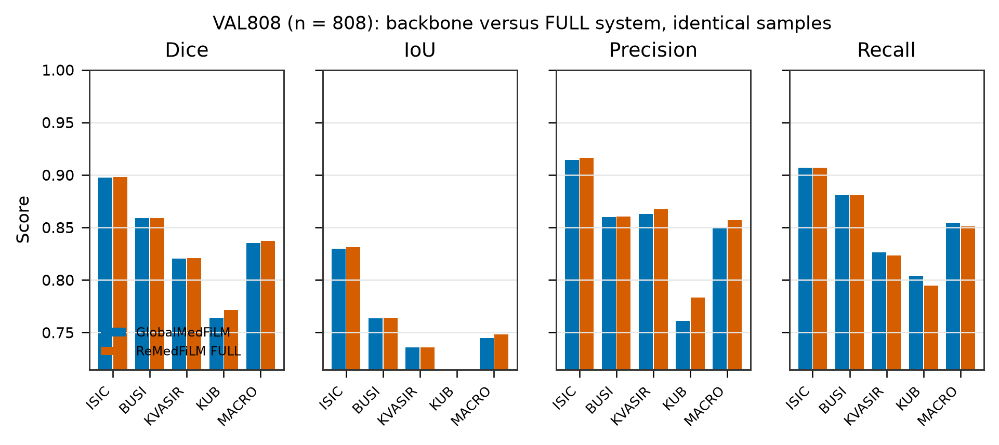

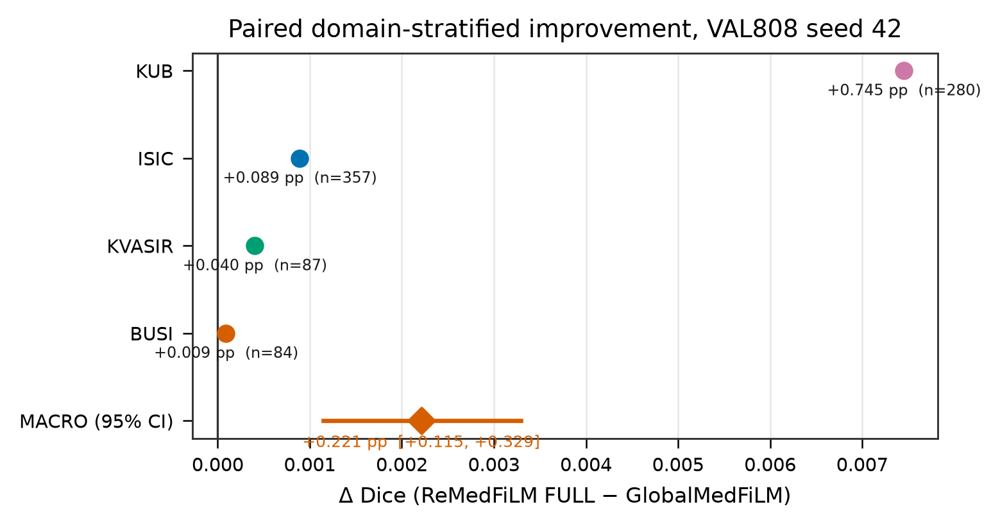

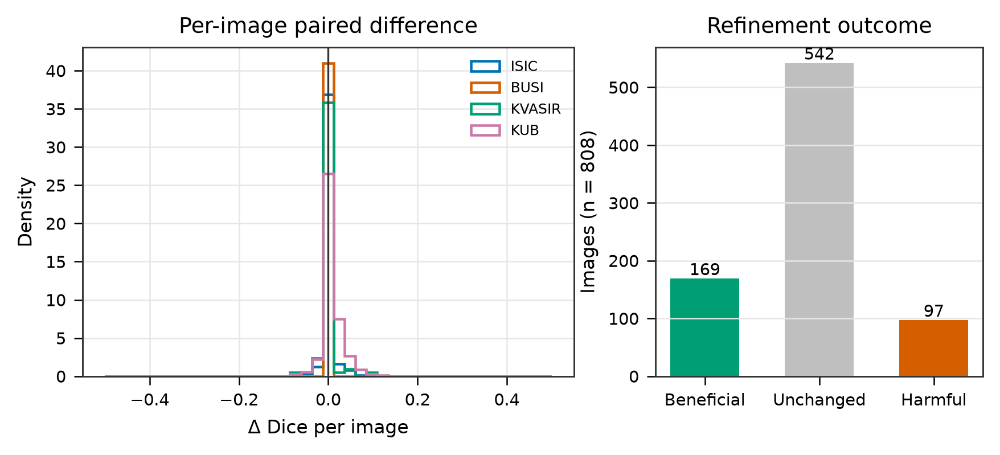

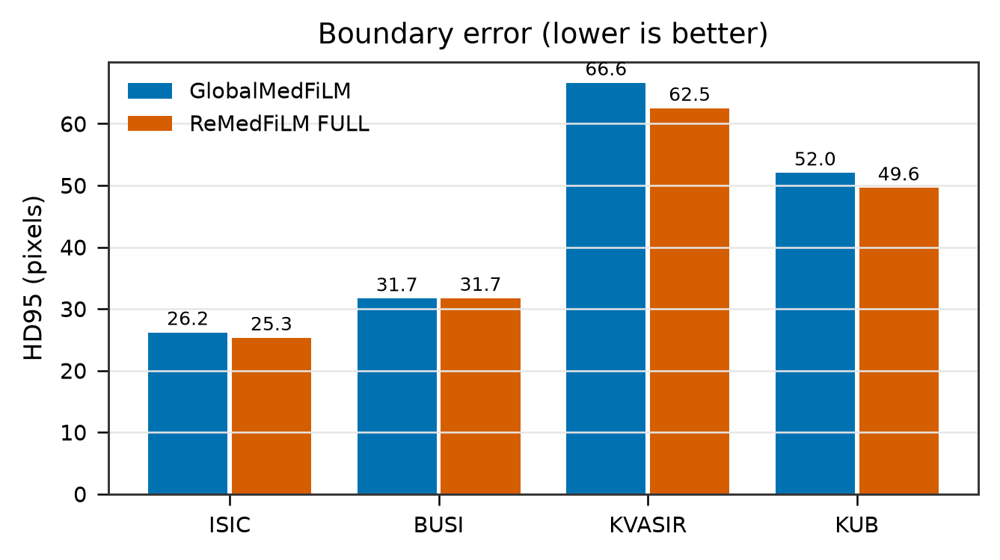

In [29]:
G.require()
for f in ["I1_domain_metric_comparison", "I2_paired_delta_forest",
          "I3_paired_delta_distribution", "I4_hd95_comparison"]:
    display(Image(filename=str(FIGURES / f"internal_evaluation/{f}.png"), width=740))

In [30]:
G.require()
ps = pd.read_csv(TABLES / "REMEDFILM_INTERNAL_PER_SAMPLE.csv")
print("outcome counts on VAL808")
print(ps.branch.value_counts().to_string())
print()
print("beneficial / unchanged / harmful:",
      int((ps.delta_dice > 1e-12).sum()),
      int((ps.delta_dice.abs() <= 1e-12).sum()),
      int((ps.delta_dice < -1e-12).sum()))
print()
print("mean delta on routed cases only: {:+.6f}".format(
    ps.loc[ps.router_decision == "EXECUTE", "delta_dice"].mean()))

outcome counts on VAL808
branch
SKIP_GLOBAL            529
EXECUTE_THEN_ACCEPT    266
EXECUTE_THEN_REJECT     13

beneficial / unchanged / harmful: 169 542 97

mean delta on routed cases only: +0.008775


---
# 08 — Class and subclass evaluation

The four domains are separate binary tasks. Within KUB the frozen size taxonomy
and stone location provide genuine subgroups; no subgroup is invented.

In [31]:
G.require()
sub = pd.read_csv(REPO / "reports/tables/phase21_kub_subgroup_analysis.csv")
sub

,scope,subgroup,n,dice,iou,precision,recall,hd95,empty_prediction_rate,role
0,KUB_ALL,KUB_ALL,280,0.764058,0.650358,0.760812,0.803676,51.880826,0.0,REPORTING_ONLY
1,KUB_SUBGROUP,Bladder_Stone,144,0.733945,0.616313,0.712706,0.793832,51.864262,0.0,REPORTING_ONLY
2,KUB_SUBGROUP,Kidney_Stone,112,0.796378,0.686368,0.823852,0.805037,51.859788,0.0,REPORTING_ONLY
3,KUB_SUBGROUP,Ureteric_Stone,24,0.793914,0.686586,0.755258,0.856392,52.078386,0.0,REPORTING_ONLY


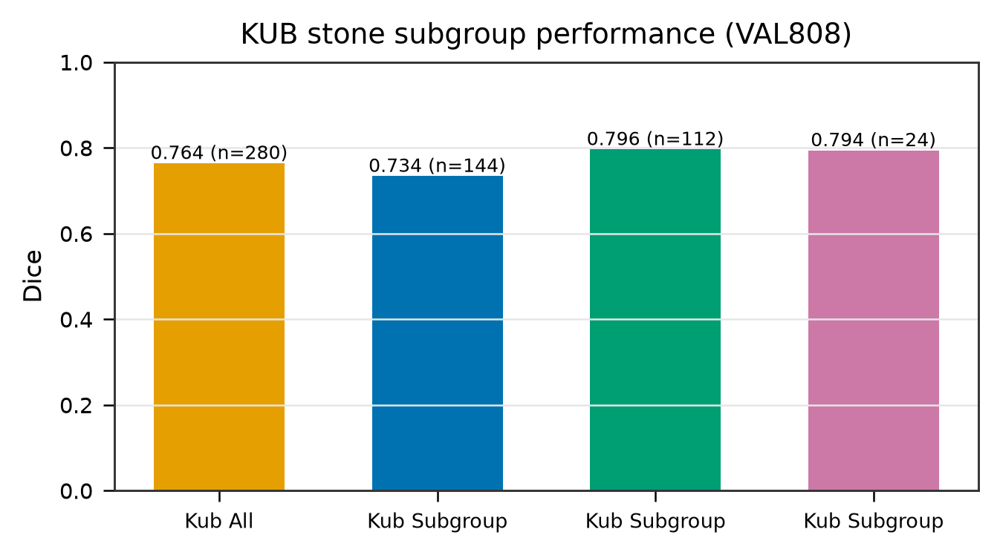

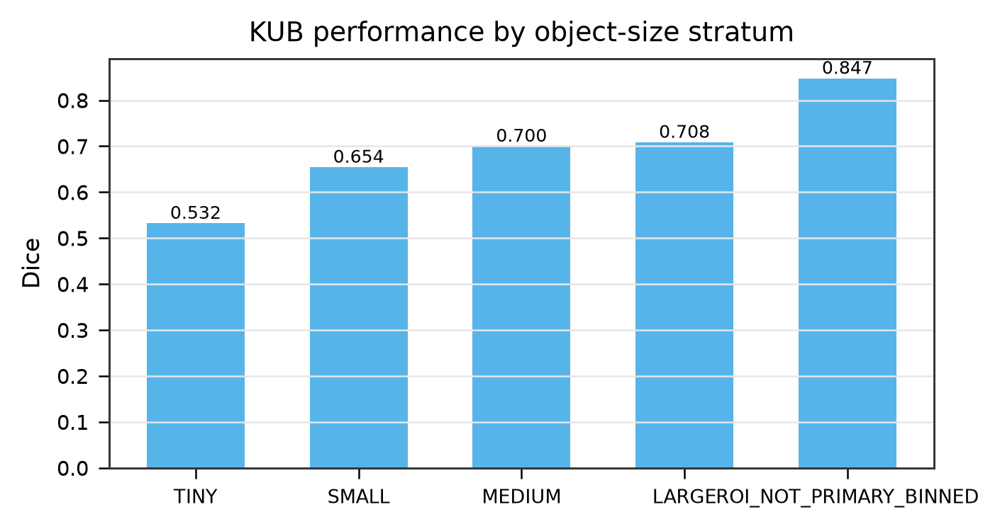

In [32]:
G.require()
display(Image(filename=str(FIGURES / "subgroups/SG1_kub_stone_subgroups.png"), width=560))
display(Image(filename=str(FIGURES / "subgroups/SG2_kub_size_stratification.png"), width=560))

In [33]:
G.require()
# BREAST subgroup labels are not present in the frozen artifacts.
print("BUSI subgroup labels  : NOT_RECORDED in any frozen artifact")
print("Polyp size categories : NOT_RECORDED per-sample")
print("KUB location/size     : RECORDED (phase21_kub_subgroup_analysis,")
print("                        phase21_kub_size_stratification)")
print()
print("No subgroup performance is inferred from final aggregates.")

BUSI subgroup labels  : NOT_RECORDED in any frozen artifact
Polyp size categories : NOT_RECORDED per-sample
KUB location/size     : RECORDED (phase21_kub_subgroup_analysis,
                        phase21_kub_size_stratification)

No subgroup performance is inferred from final aggregates.


---
# 09 — Semantic segmentation gallery

Selection rule, fixed in advance and applied mechanically: within each domain,
sort the 808 samples by paired Δ Dice and take the **worst**, **median** and
**best** case. No manual cherry-picking.

Panels: original image · evaluation ground truth · GlobalMedFiLM mask ·
ReMedFiLM FULL mask · TP/FP/FN overlay (green = TP, orange = FP, blue = FN).

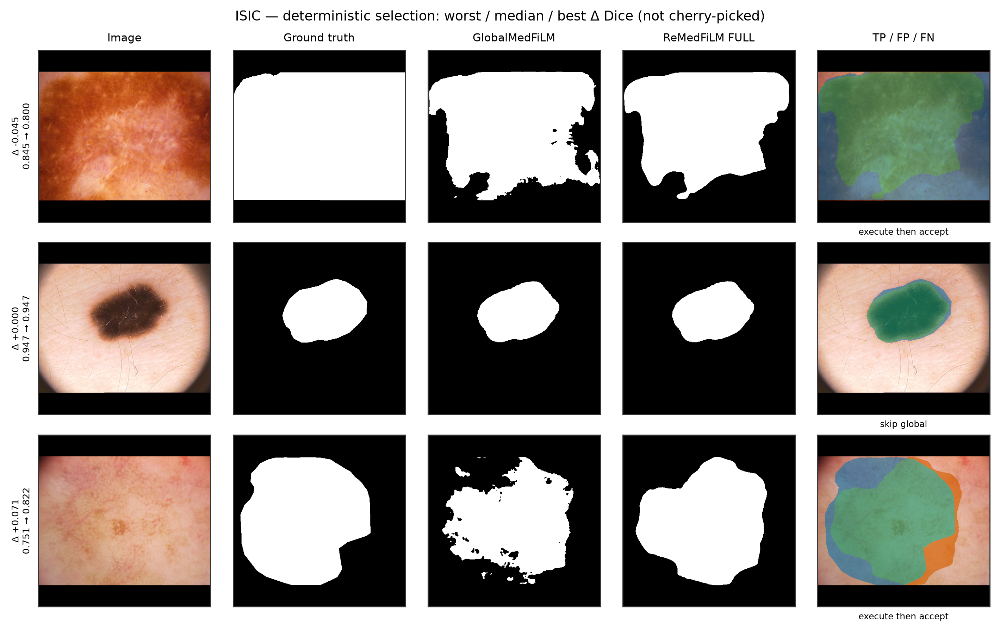

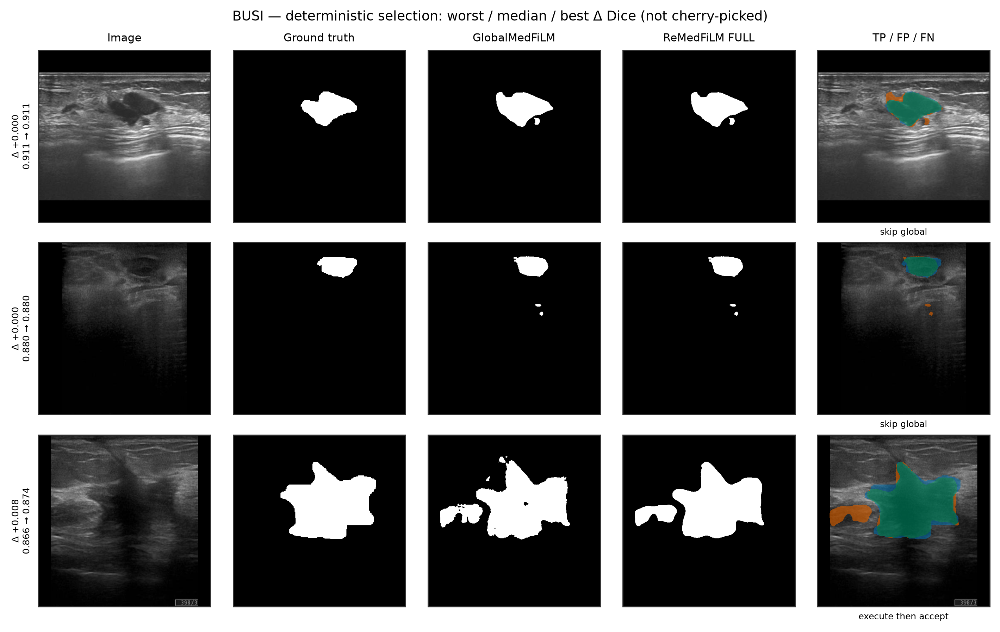

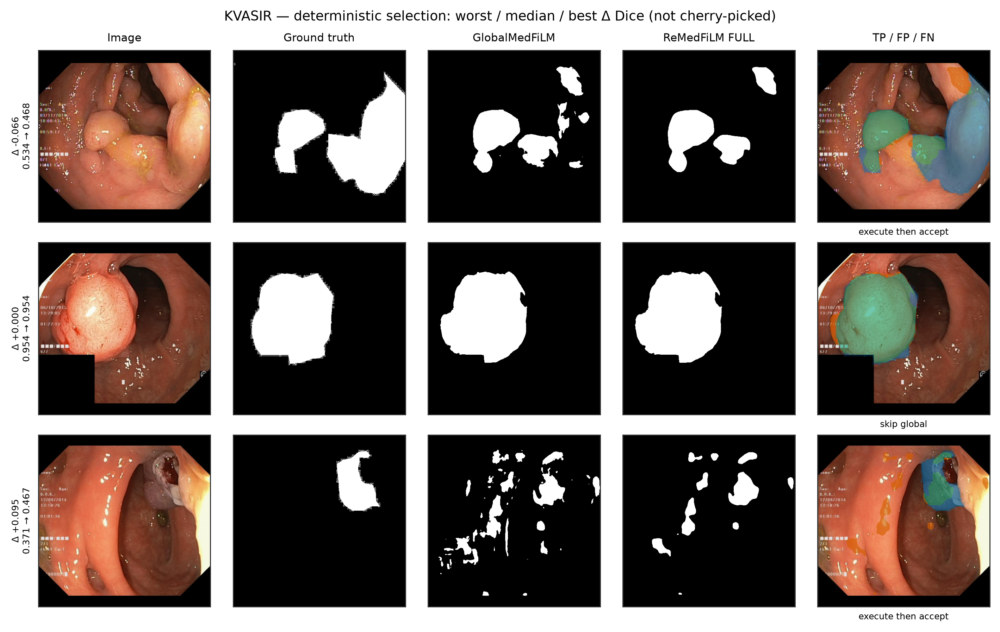

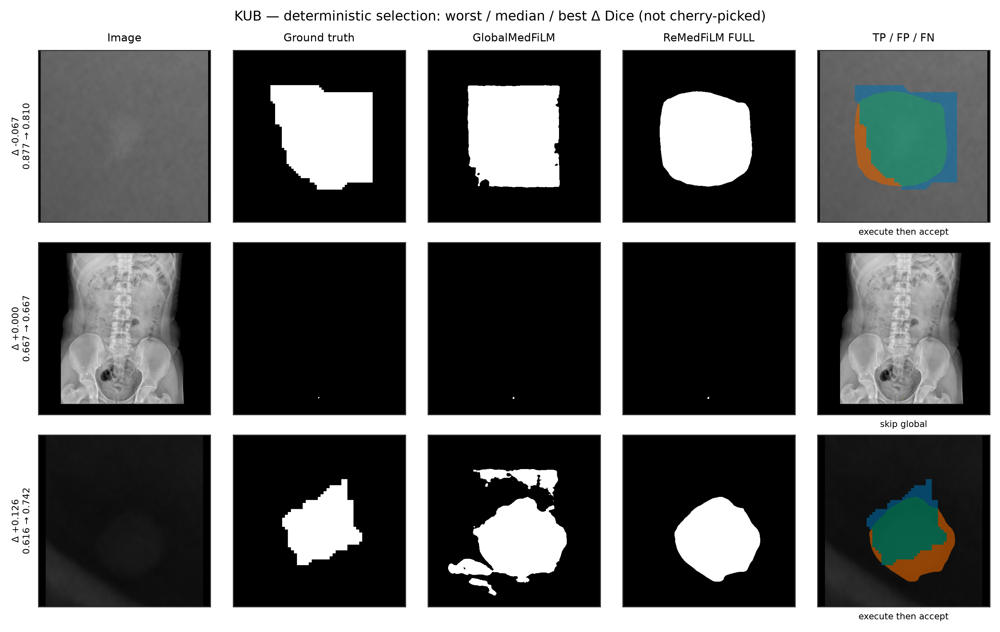

In [34]:
G.require()
for dom in ["ISIC", "BUSI", "KVASIR", "KUB"]:
    display(Image(filename=str(FIGURES / f"segmentation/SEG_{dom}_global_vs_full.png"), width=880))

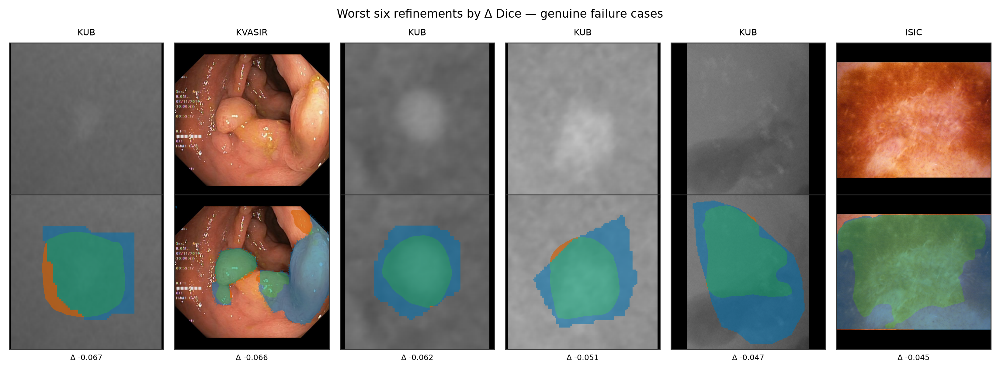

In [35]:
G.require()
display(Image(filename=str(FIGURES / "segmentation/SEG_failure_cases.png"), width=900))

In [36]:
G.require()
# Confirm the gallery images are genuine and aligned: GT is confined to the
# letterboxed region, exactly as the evaluation contract defines.
sample = ps.sort_values("delta_dice").iloc[0]
print("worst case:", sample.sample_id, sample.domain, f"Δ={sample.delta_dice:+.4f}")
print("branch    :", sample.branch)
print("This is a genuine residual failure: the safety gate accepted a refinement")
print("that reduced Dice.")

worst case: fd8f2744680aa3a805f47a8151ef9761 KUB Δ=-0.0674
branch    : EXECUTE_THEN_ACCEPT
This is a genuine residual failure: the safety gate accepted a refinement
that reduced Dice.


---
# 10 — External retrospective evaluation (884 cases)

CVC-ClinicDB (612), BrEaST-Lesions-USG (252) and Stones-Where-Are-You (20).
These are **separate cohorts** with different reference standards; they are never
pooled with VAL808 or with each other.

The stone-free subset is a documented **negative result**: every case receives
foreground.

In [37]:
G.require()
ext = pd.read_csv(TABLES / "REMEDFILM_EXTERNAL_METRICS.csv")
ext[ext.metric == "Dice"][["cohort", "arm", "n_total", "n_defined", "mean",
                           "median", "ci_low", "ci_high", "n_clusters"]].to_string(index=False)

'              cohort            arm  n_total  n_defined     mean   median   ci_low  ci_high  n_clusters\n        CVC-ClinicDB  GlobalMedFiLM      612        612 0.686568 0.771761 0.626485 0.743686        29.0\n        CVC-ClinicDB ReMedFiLM_FULL      612        612 0.689747 0.774735 0.629797 0.746428        29.0\n  BrEaST-Lesions-USG  GlobalMedFiLM      252        252 0.707822 0.813238 0.676828 0.737830       252.0\n  BrEaST-Lesions-USG ReMedFiLM_FULL      252        252 0.708098 0.813238 0.677001 0.738037       252.0\nStones_where_are_you  GlobalMedFiLM       20         20 0.080840 0.000000 0.003360 0.189947        20.0\nStones_where_are_you ReMedFiLM_FULL       20         20 0.082126 0.000000 0.004646 0.191239        20.0'

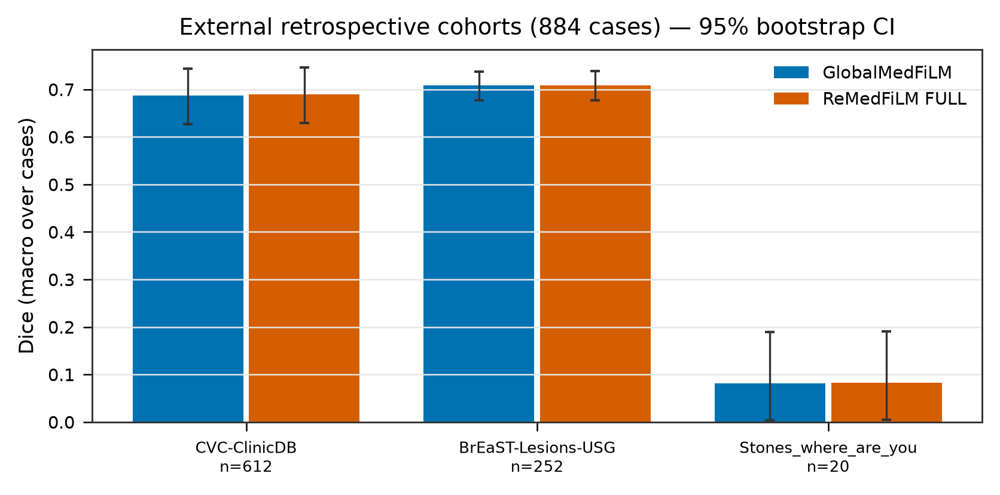

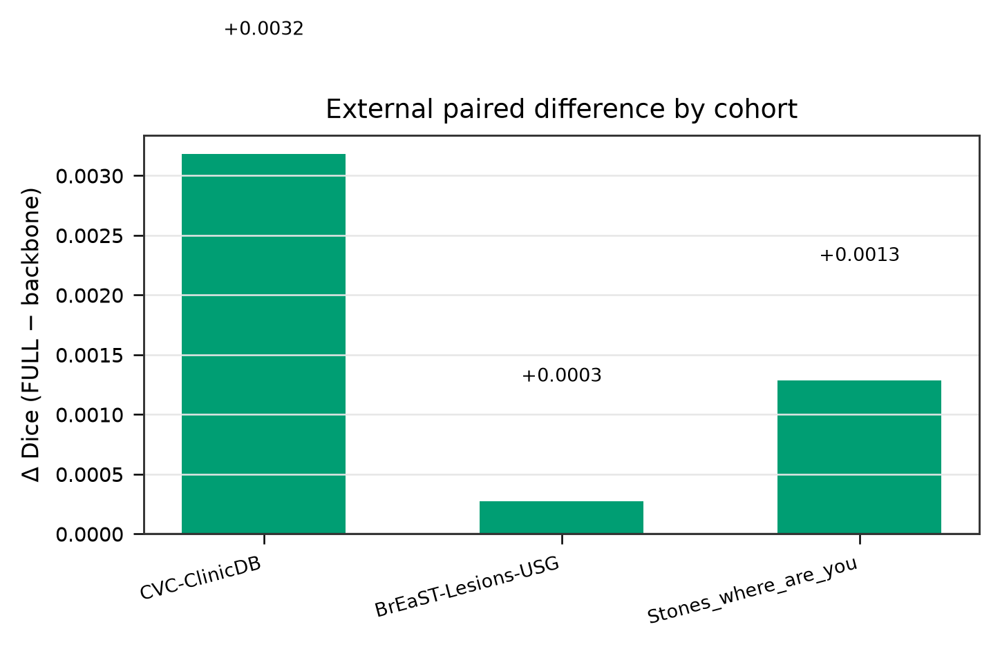

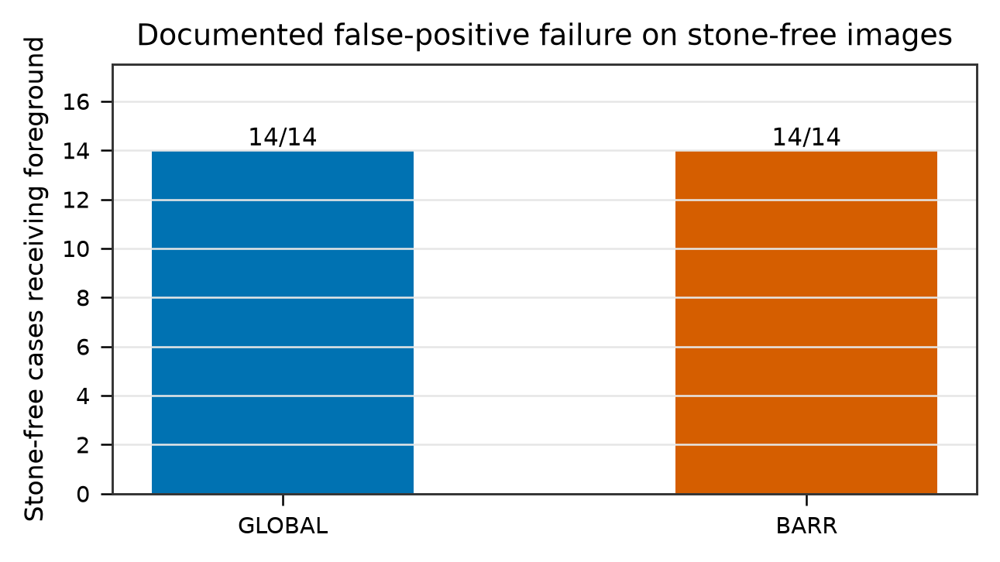

In [38]:
G.require()
display(Image(filename=str(FIGURES / "external_evaluation/EXT01_external_dice.png"), width=700))
display(Image(filename=str(FIGURES / "external_evaluation/EXT02_external_delta.png"), width=560))
display(Image(filename=str(FIGURES / "external_evaluation/EXT03_stonefree_false_positive.png"), width=520))

In [39]:
G.require()
pc = pd.read_csv(REPO / "reports/tables/c1_external_stress_per_case.csv")
sf = pc[pc.gt_empty.astype(str).str.lower() == "true"]
print("stone-free cases:", len(sf))
if len(sf):
    for arm, grp in sf.groupby("arm"):
        got_fg = (grp.pred_empty.astype(str).str.lower() == "false").sum()
        print(f"  {arm:8s}: {got_fg}/{len(grp)} receive foreground")
print()
print("HD95 / ASSD are undefined for empty-reference cases and are reported as")
print("missing, never as zero.")

stone-free cases: 28
  barr    : 14/14 receive foreground
  global  : 14/14 receive foreground

HD95 / ASSD are undefined for empty-reference cases and are reported as
missing, never as zero.


---
# 11 — Component progression

Stages are **not** a controlled ablation. Stage 0 is VAL808; stages 1–3 are
ROUTER_DEVELOPMENT (4,957); stage 4 returns to VAL808. Populations differ and
must not be read as a single monotone experiment.

In [40]:
G.require()
prog = pd.read_csv(TABLES / "REMEDFILM_PROGRESSION_RESULTS.csv")
prog

,stage,stage_name,population,n,active_components,mean_dice,routed_fraction,accepted_fraction,net_delta_pp,harm_rate,gmacs_lower_bound,evidence_class,source
0,Stage 0,GlobalMedFiLM backbone (G),VAL808,808,G,0.83508,0.000000,0.000000,0.000000,0.000000,31.551741,FROZEN_BACKBONE_REFERENCE,reports/tables/phase21_six_model_comparison.csv
1,Stage 1,Unrouted regional refinement (A1),ROUTER_DEVELOPMENT_4957,4957,G + R_psi,NaN,1.000000,1.000000,0.165808,0.426669,34.782441,IN_SAMPLE_ENDPOINT_BY_CONSTRUCTION,reports/tables/phase28_table_02_arm_primary_me...
2,Stage 2,Learned benefit routing (A7),ROUTER_DEVELOPMENT_4957,4957,G + R_psi + B_phi,NaN,0.249950,0.249950,0.724663,0.332526,32.437902,DEVELOPMENT_EVIDENCE,reports/tables/phase28_table_02_arm_primary_me...
3,Stage 3,Post-safety gate (A8 FULL),ROUTER_DEVELOPMENT_4957,4957,G + R_psi + B_phi + S_omega,NaN,0.243091,0.243091,0.751575,0.323651,32.437902,DEVELOPMENT_EVIDENCE,reports/tables/phase28_table_02_arm_primary_me...
4,Stage 4,FULL assembly on held-out VAL808,VAL808,808,G + R_psi + B_phi + S_omega,0.83729,0.345297,0.329208,0.220997,0.120050,32.437902,PAIRED_PRESERVATION_EVIDENCE,reports/tables/phase27_val808_predictions.csv ...
5,Audit gate,Incremental dataset progression,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NOT_EXECUTED,no genuine incremental-domain training study e...


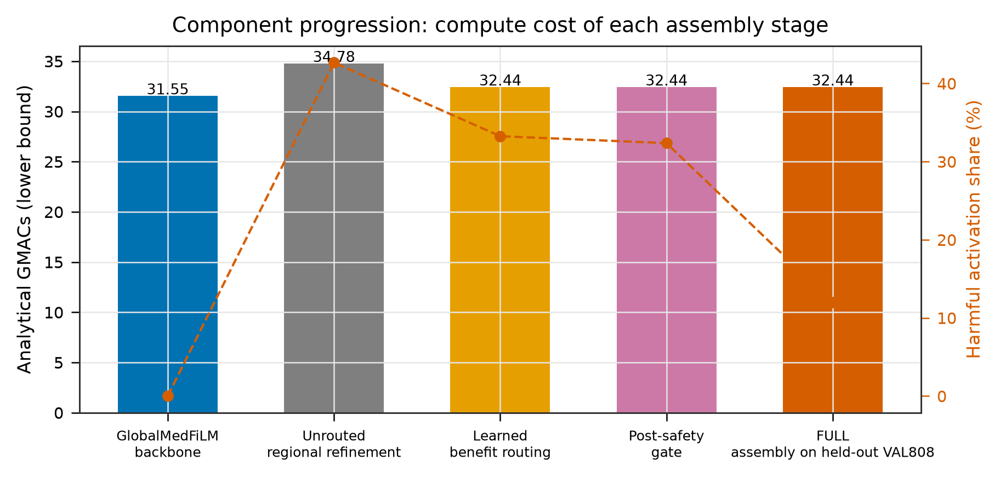

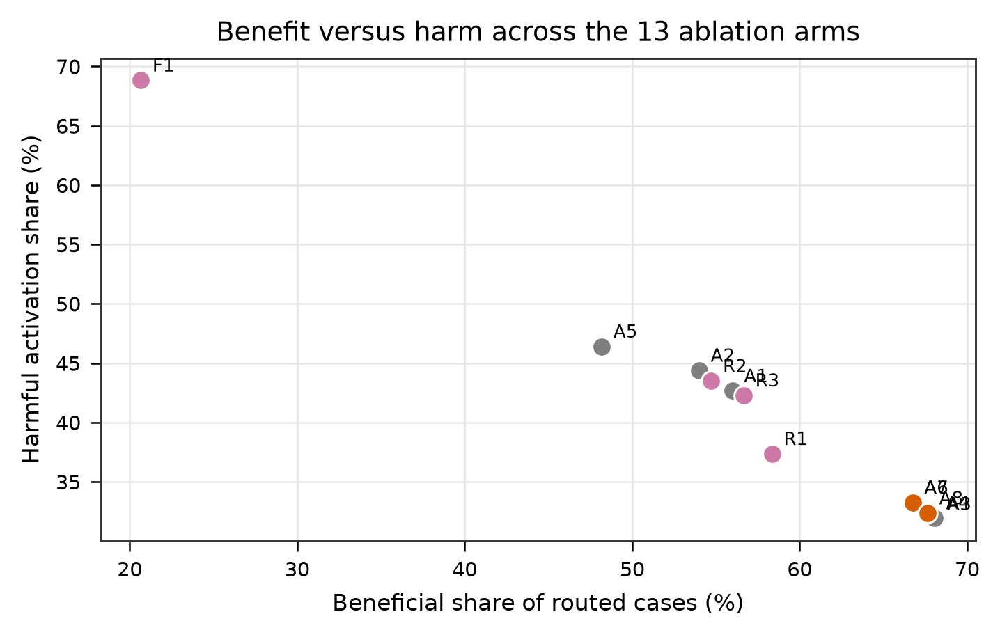

In [41]:
G.require()
display(Image(filename=str(FIGURES / "progression/PROG01_stage_compute_and_harm.png"), width=720))
display(Image(filename=str(FIGURES / "progression/PROG02_benefit_harm_tradeoff.png"), width=600))

In [42]:
G.require()
print("No genuine incremental-domain training study exists in the repository.")
print("The 'incremental dataset progression' audit gate is NOT_EXECUTED and is")
print("recorded as such in REMEDFILM_PROGRESSION_RESULTS.csv.")

No genuine incremental-domain training study exists in the repository.
The 'incremental dataset progression' audit gate is NOT_EXECUTED and is
recorded as such in REMEDFILM_PROGRESSION_RESULTS.csv.


---
# 12 — Complete ablation study (Phase 28, 13 arms)

A0–A8, R1–R3 and F1 on ROUTER_DEVELOPMENT (4,957; budget K = 1,239).

**Preserved finding:** the only pre-specified matched contrast, **A8 vs A7**,
has a 95% CI that **includes zero**. It is reported as inconclusive, not as a win.

In [43]:
G.require()
abl = pd.read_csv(TABLES / "REMEDFILM_ABLATION_RESULTS.csv")
abl[["arm", "n_routed", "budget_fraction", "mean_true_delta_dice_routed",
     "benefit_capture_vs_positive_mass", "harmful_activation_share",
     "evidence_class"]].to_string(index=False)

'arm  n_routed  budget_fraction  mean_true_delta_dice_routed  benefit_capture_vs_positive_mass  harmful_activation_share                   evidence_class\n A0         0         0.000000                     0.000000                          0.000000                  0.000000         ENDPOINT_BY_CONSTRUCTION\n A1      4957         1.000000                     0.001658                          1.000000                  0.426669         ENDPOINT_BY_CONSTRUCTION\n A2      1239         0.249950                     0.001413                          0.245520                  0.443906   PRIOR_CANONICAL_EVIDENCE_EXACT\n A3      1239         0.249950                     0.007185                          0.584331                  0.318805   PRIOR_CANONICAL_EVIDENCE_EXACT\n A4      1239         0.249950                     0.007119                          0.582158                  0.319613   PRIOR_CANONICAL_EVIDENCE_EXACT\n A5      1239         0.249950                    -0.000433                

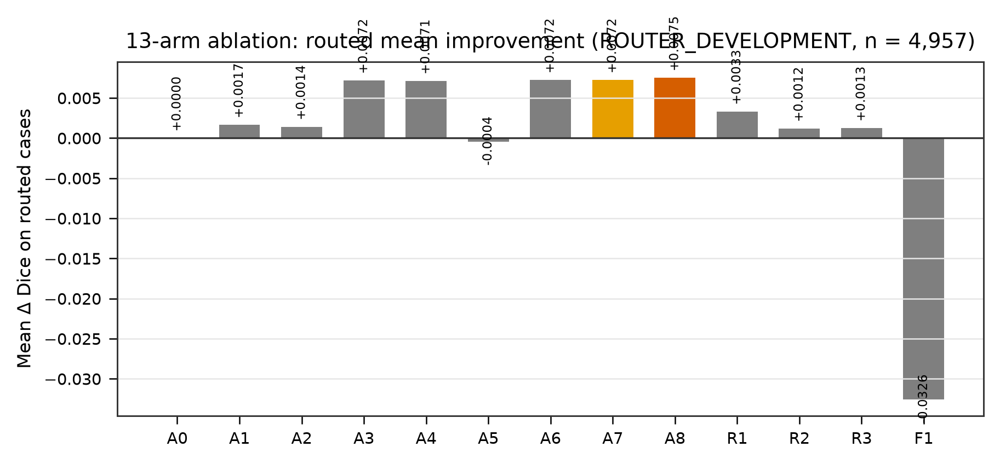

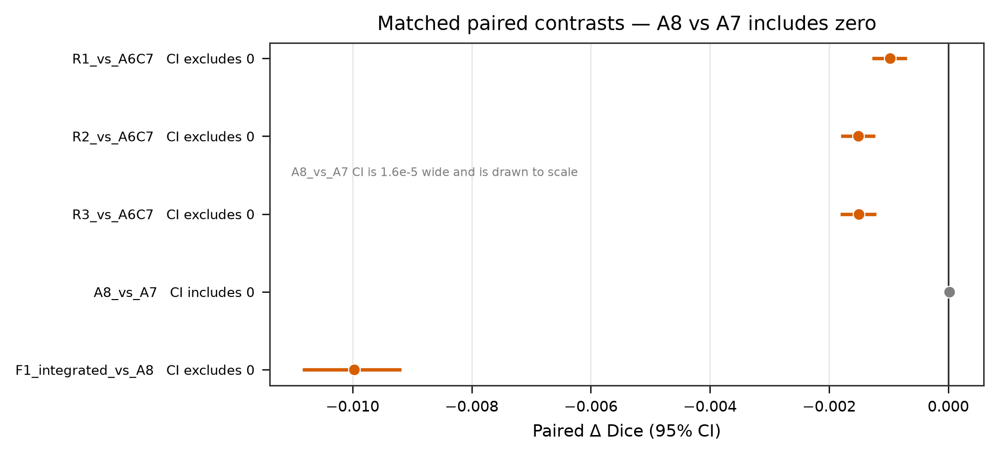

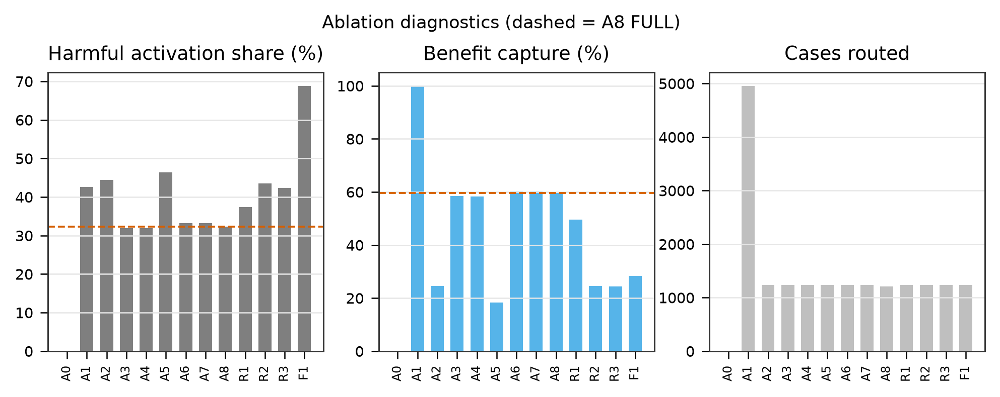

In [44]:
G.require()
display(Image(filename=str(FIGURES / "ablation/ABL01_arm_mean_delta.png"), width=760))
display(Image(filename=str(FIGURES / "ablation/ABL02_paired_contrasts_forest.png"), width=620))
display(Image(filename=str(FIGURES / "ablation/ABL03_ablation_diagnostics.png"), width=860))

In [45]:
G.require()
bs = pd.read_csv(REPO / "reports/tables/phase28_table_08_bootstrap_statistics.csv")
bs[["contrast", "n", "mean_difference", "ci95_low", "ci95_high"]].to_string(index=False)
print()
a8 = bs[bs.contrast == "A8_vs_A7"].iloc[0]
print("A8 vs A7 : {:+.3e} [{:+.3e}, {:+.3e}]".format(
    a8.mean_difference, a8.ci95_low, a8.ci95_high))
print("CI includes zero:", not (a8.ci95_low > 0 or a8.ci95_high < 0))


A8 vs A7 : +1.572e-05 [-1.431e-05, +5.101e-05]
CI includes zero: True


---
# 13 — Error propagation and routing analysis

Counts are exact, not modelled: 808 global forwards, 279 ROI selections,
266 accepted refinements and 13 rejections that fall back to the backbone.

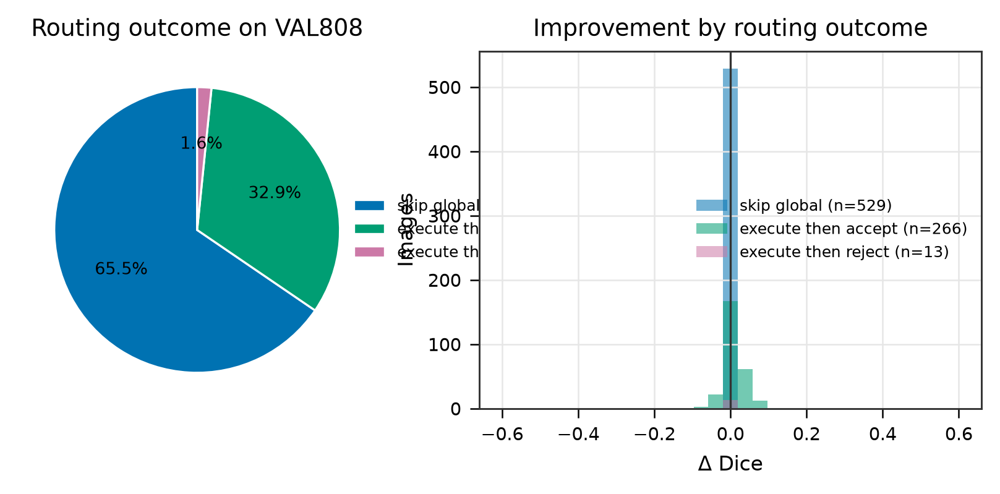

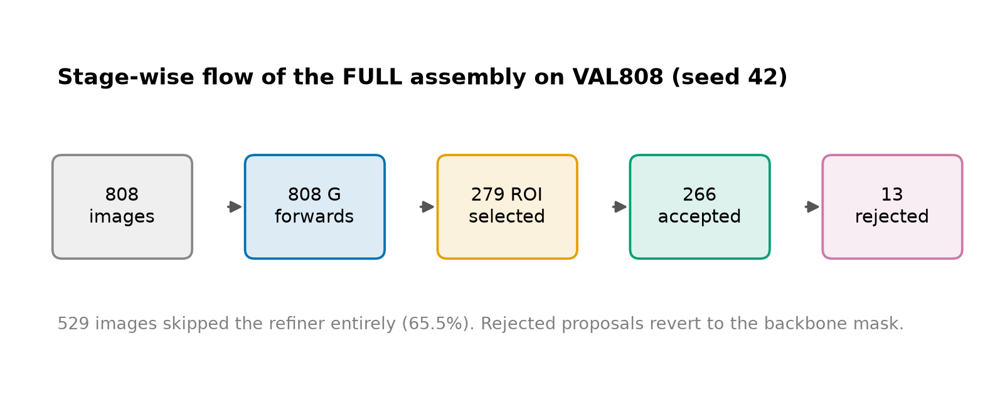

In [46]:
G.require()
display(Image(filename=str(FIGURES / "routing_safety/RT01_routing_outcomes.png"), width=740))
display(Image(filename=str(FIGURES / "routing_safety/RT02_stage_flow.png"), width=720))

In [47]:
G.require()
tab = ps.groupby("branch").agg(
    n=("sample_id", "size"),
    mean_delta=("delta_dice", "mean"),
    harmful=("delta_dice", lambda s: int((s < -1e-12).sum())),
    beneficial=("delta_dice", lambda s: int((s > 1e-12).sum())),
).reset_index()
tab["share"] = (tab.n / len(ps)).round(4)
tab

,branch,n,mean_delta,harmful,beneficial,share
0,EXECUTE_THEN_ACCEPT,266,0.009204,97,169,0.3292
1,EXECUTE_THEN_REJECT,13,0.000000,0,0,0.0161
2,SKIP_GLOBAL,529,0.000000,0,0,0.6547


In [48]:
G.require()
print("ROUTER_DEVELOPMENT and EXTERNAL884 are kept separate in every table.")
print("No routing statistic in this notebook mixes those populations with VAL808.")
print()
print("VAL808 (this section) : 808 images, 279 routed, 266 accepted")
print("ROUTER_DEV (section 12): 4,957 images, 1,239 routed, 1,205 accepted")

ROUTER_DEVELOPMENT and EXTERNAL884 are kept separate in every table.
No routing statistic in this notebook mixes those populations with VAL808.

VAL808 (this section) : 808 images, 279 routed, 266 accepted
ROUTER_DEV (section 12): 4,957 images, 1,239 routed, 1,205 accepted


---
# 14 — Robustness and interpretability

Phase 36 executed 12,928 perturbation instances over the 808 clean images
(12 conditions), with `test_reads = 0`, `training = 0`, `optimizer_steps = 0`.
The clean-equivalence gate reproduced the frozen predictions exactly.

In [49]:
G.require()
r36 = json.loads((REPO / "reports/audits/phase36_robustness_scientific_result_v1_23.json").read_text(encoding="utf-8"))
print("counters")
for k in ("clean_passes", "perturbed_g_forwards", "test_reads", "training",
          "optimizer_steps", "parameter_mutations", "router_holdout_reads"):
    print(f"  {k:22s}: {r36['counters'][k]}")
print()
ce = r36["clean_equivalence"]
print("clean equivalence all_pass:", ce["all_pass"])
print("dice mismatches           :", len(ce["dice_mismatches"]))
print("max |Δ Dice| vs frozen    :", ce.get("max_abs_dice_difference", 0.0))

counters
  clean_passes          : 808
  perturbed_g_forwards  : 12928
  test_reads            : 0
  training              : 0
  optimizer_steps       : 0
  parameter_mutations   : 0
  router_holdout_reads  : 0

clean equivalence all_pass: True
dice mismatches           : 0
max |Δ Dice| vs frozen    : 0.0


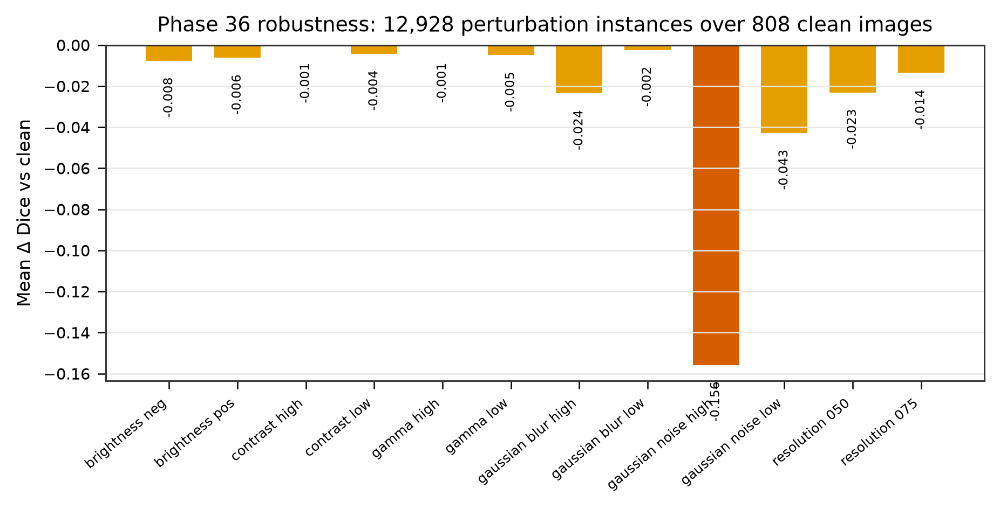

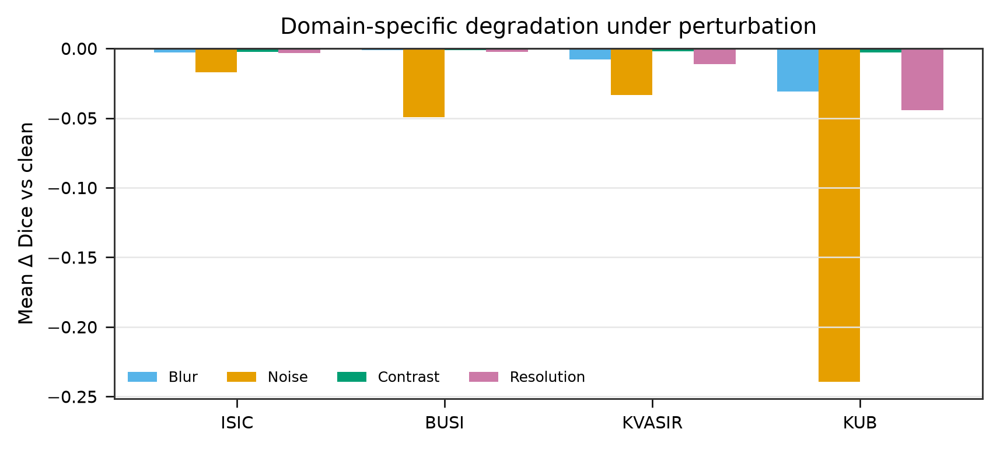

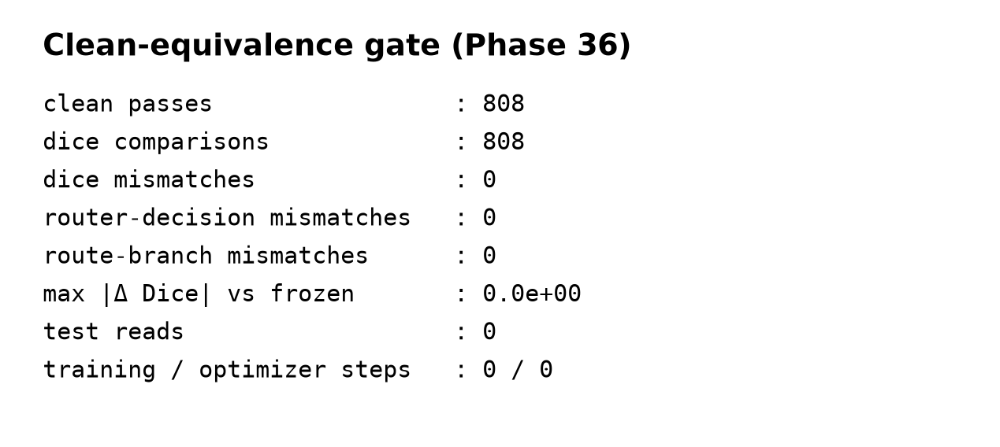

In [50]:
G.require()
display(Image(filename=str(FIGURES / "robustness/ROB01_perturbation_degradation.png"), width=780))
display(Image(filename=str(FIGURES / "robustness/ROB02_domain_degradation.png"), width=700))
display(Image(filename=str(FIGURES / "robustness/ROB03_clean_equivalence_gate.png"), width=560))

In [51]:
G.require()
wc = pd.DataFrame(r36["worst_case_by_domain"])
wc

,domain,n_samples,worst_image_delta_Dice_min,worst_image_delta_Dice_mean
0,BUSI,84,-0.873057,-0.142196
1,ISIC,357,-0.874958,-0.063719
2,KUB,280,-0.921131,-0.413650
3,KVASIR,87,-0.489964,-0.102712


In [52]:
G.require()
# Phase 35 interpretability — report what exists and what does not.
p35 = json.loads((REPO / "reports/audits/phase35_interpretability_scientific_result_v1_0.json").read_text(encoding="utf-8"))
print("Phase 35 terminal:", p35.get("terminal_state", p35.get("status", "PRESENT")))
for k, v in list(p35.items())[:10]:
    if not isinstance(v, (dict, list)):
        print(f"  {k}: {v}")

Phase 35 terminal: PRESENT
  artifact: phase35_interpretability_scientific_result_v1_0
  section: §V
  phase: 35
  method: RA-MedFiLM-BARR
  revision: ra_medfilm_barr_phase35_interpretability_v1_0
  classification: PHASE35_FIRST_SCIENTIFIC_EXECUTION_RESULT
  claim_type: DESCRIPTIVE_MODEL_MECHANISM_EVIDENCE
  families_never_merged: True


---
# 15 — Computational efficiency

| | GlobalMedFiLM | ReMedFiLM FULL |
|---|---|---|
| Parameters | 3,523,001 | 4,837,420 |
| Analytical GMACs | 31.5517 (lower bound) | 32.4379 (expected conditional) |
| VAL808 macro Dice | 0.835079 | 0.837290 |
| Batch-1 p50 (skip / execute) | 15.72 ms | 18.89 ms |

The expected conditional cost is the routing-weighted cost
`31.5517 + 0.243 × 3.646`, not the always-refine cost of 34.78 GMACs.

In [53]:
G.require()
eff = pd.read_csv(TABLES / "REMEDFILM_EFFICIENCY.csv")
eff

,model,params,gmacs,gmacs_semantics,latency_p50_ms,latency_p50_semantics,macro_dice,population,source
0,GlobalMedFiLM (G),3523001,31.551700,ANALYTICAL_LOWER_BOUND,15.721472,MEASURED_BATCH1_CONTROLLED_FORWARD,0.835079,VAL808,phase21_analytical_mac_count.json / phase34_ef...
1,ReMedFiLM (FULL),4837420,32.437902,EXPECTED_CONDITIONAL,18.886640,MEASURED_BATCH1_CONTROLLED_FORWARD,0.837290,VAL808,phase34_parameter_count_contract.json / c2_bar...
2,DeepLabV3+,40347041,NaN,NOT_RECORDED,NaN,NOT_RECORDED,0.827652,VAL808,reports/tables/phase21_six_model_comparison.csv
3,Transformer/MiT-style U-Net,16347777,NaN,NOT_RECORDED,NaN,NOT_RECORDED,0.822383,VAL808,reports/tables/phase21_six_model_comparison.csv
4,U-Net++,9159681,NaN,NOT_RECORDED,NaN,NOT_RECORDED,0.792010,VAL808,reports/tables/phase21_six_model_comparison.csv
5,Attention U-Net,7851285,NaN,NOT_RECORDED,NaN,NOT_RECORDED,0.789037,VAL808,reports/tables/phase21_six_model_comparison.csv
6,U-Net,7763041,NaN,NOT_RECORDED,NaN,NOT_RECORDED,0.787832,VAL808,reports/tables/phase21_six_model_comparison.csv


In [54]:
G.require()
c2 = json.loads((REPO / "reports/tables/c2_barr/c2_barr_aggregate.json").read_text(encoding="utf-8"))
g = c2["compute"]["analytical_gmacs_lower_bound"]
for k in ("LITERAL_GLOBAL_ONLY_C1", "FINAL_A8_C9_EXPECTED_CONDITIONAL",
          "LITERAL_ALWAYS_REFINE_C2", "SAVING_vs_literal_C2"):
    print(f"  {k:34s}: {g[k]}")
print()
print("saving versus always-refine: {:.4f} GMACs ({:.1%} of always-refine)".format(
    g["SAVING_vs_literal_C2"],
    g["SAVING_vs_literal_C2"] / g["LITERAL_ALWAYS_REFINE_C2"]))

  LITERAL_GLOBAL_ONLY_C1            : 31.551740928
  FINAL_A8_C9_EXPECTED_CONDITIONAL  : 32.437902022582854
  LITERAL_ALWAYS_REFINE_C2          : 34.782403584
  SAVING_vs_literal_C2              : 2.344501561417145

saving versus always-refine: 2.3445 GMACs (6.7% of always-refine)


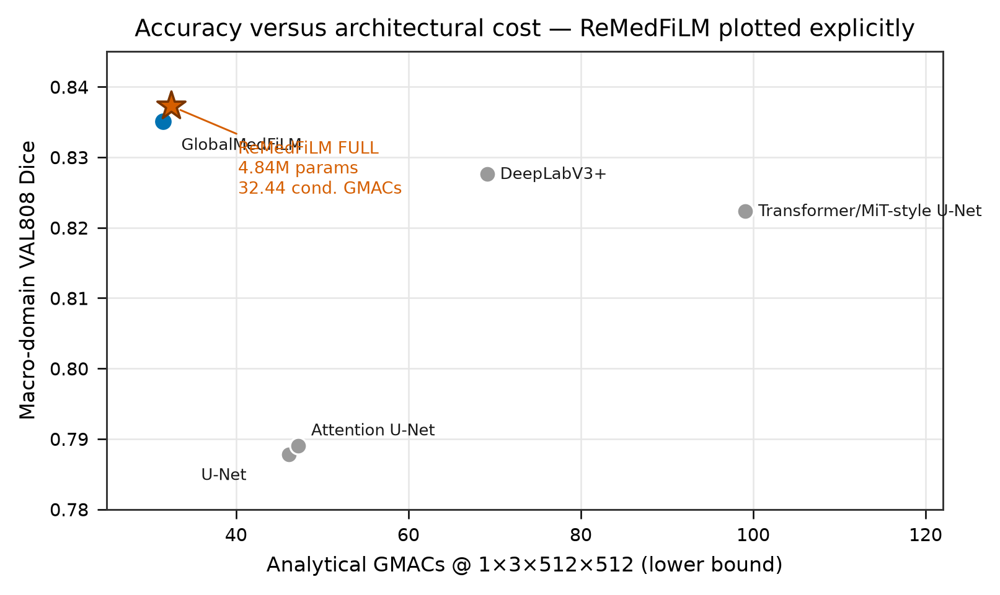

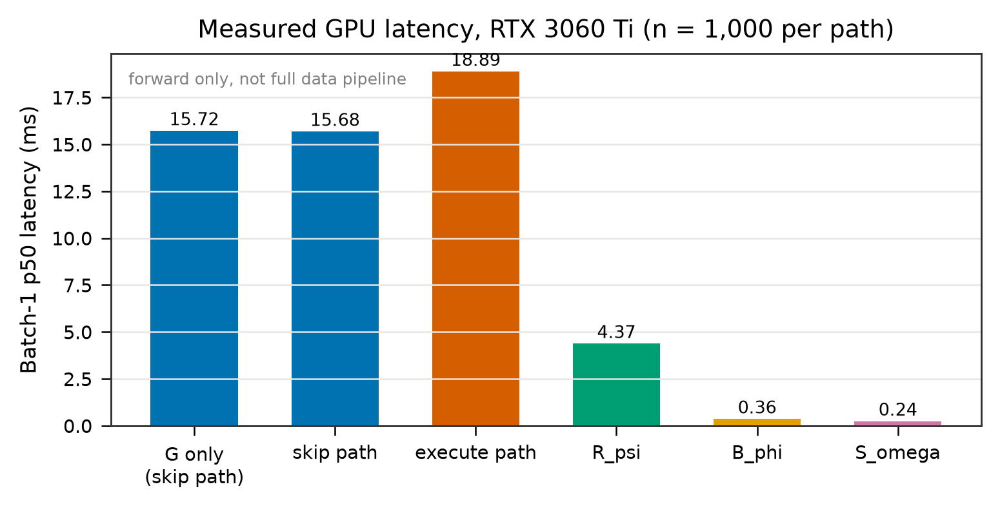

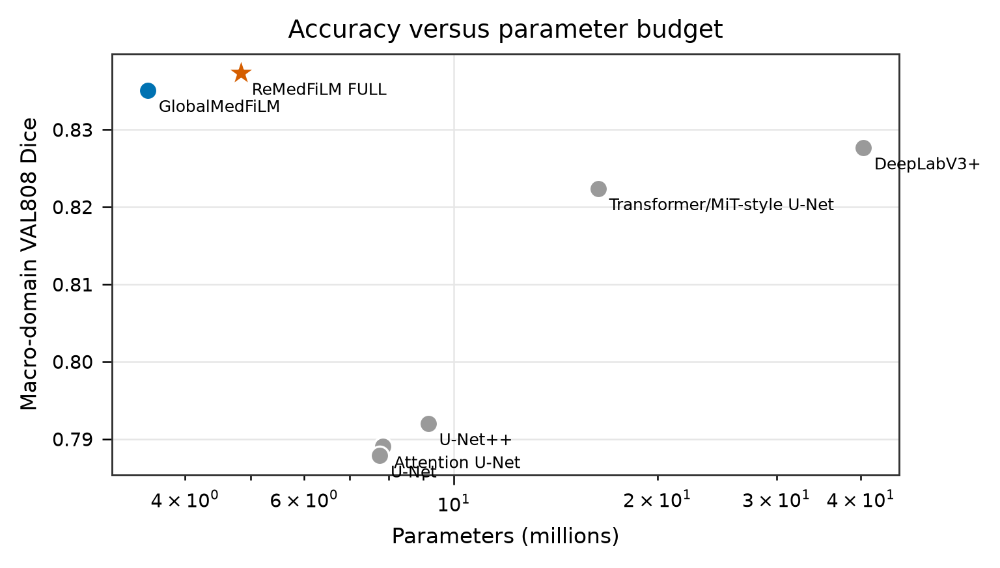

In [55]:
G.require()
display(Image(filename=str(FIGURES / "efficiency/EFF01_accuracy_vs_compute.png"), width=720))
display(Image(filename=str(FIGURES / "efficiency/EFF02_latency_breakdown.png"), width=700))
display(Image(filename=str(FIGURES / "efficiency/EFF03_accuracy_vs_parameters.png"), width=600))

In [56]:
G.require()
print("Timing semantics — do not conflate:")
print("  analytical GMACs      : closed-form Conv2d/Linear count, LOWER BOUND")
print("  measured batch-1 p50  : GPU forward only, RTX 3060 Ti, n=1,000")
print("  full pipeline latency : NOT_RECORDED (data loading + preprocessing excluded)")
print()
print("The manuscript's 18.89 ms is the execute-path forward, not an end-to-end")
print("pipeline figure.")

Timing semantics — do not conflate:
  analytical GMACs      : closed-form Conv2d/Linear count, LOWER BOUND
  measured batch-1 p50  : GPU forward only, RTX 3060 Ti, n=1,000
  full pipeline latency : NOT_RECORDED (data loading + preprocessing excluded)

The manuscript's 18.89 ms is the execute-path forward, not an end-to-end
pipeline figure.


---
# 16 — Historical TEST evidence

TEST1683 was evaluated **once**, historically, and that one-shot access is
consumed. This notebook does not open it. The only numbers below are read from
the frozen descriptive result file.

There is **no comparative endpoint** for C1/C2/C3 on TEST, because no such
experiment was authorised.

In [57]:
G.require()
p39 = json.loads((REPO / "reports/audits/phase39_final_test_v1_2_scientific_result.json").read_text(encoding="utf-8"))
print("keys:", list(p39.keys())[:14])
for k, v in p39.items():
    if not isinstance(v, (dict, list)):
        print(f"  {k}: {v}")

keys: ['classification', 'evidence_class', 'revision', 'phase', 'method', 'generated_utc', 'population', 'test_n', 'component_load_audit', 'counters', 'summary', 'phase30_qualifier', 'source_sha256', 'manifest_schema_domain_field']
  classification: PHASE39_FINAL_TEST_SCIENTIFIC_RESULT
  evidence_class: POST_PROTOCOL_TECHNICAL_RECOVERY_TEST_RESULT_WITH_TWO_DISCLOSED_PREOUTCOME_TECHNICAL_FAILURES
  revision: ra_medfilm_barr_phase39_final_test_v1_2
  phase: 39
  method: RA-MedFiLM-BARR
  generated_utc: 2026-10-11T10:09:40Z
  population: TEST
  test_n: 1683
  phase30_qualifier: ONE_SHOT_ROUTER_HOLDOUT_RESULT_WITH_DISCLOSED_POST_FIRST_OPEN_SCIENTIFIC_SOURCE_FREEZE_DEVIATION
  source_sha256: e3544634095d86853ce0e7b2fa55bac4a0ecf84cef65ea6fab163a1466606d3c
  manifest_schema_domain_field: dataset


In [58]:
G.require()
import pandas as pd
dom = p39.get("per_domain") or p39.get("domains") or []
if isinstance(dom, dict):
    dom = [{"domain": k, **v} for k, v in dom.items()]
if dom:
    df = pd.DataFrame(dom)
    print(df.to_string(index=False))
    print()
    print("descriptive only — no C1/C2/C3 contrast exists on TEST")
else:
    print("per-domain block not present in the frozen result")

per-domain block not present in the frozen result


---
# 17 — Scientific conclusions and missing evidence

Established, descriptive, and missing are kept strictly apart.

In [59]:
G.require()
summary = pd.DataFrame([
    {"claim": "GlobalMedFiLM backbone VAL808 macro Dice 0.835079", "status": "ESTABLISHED",
     "evidence": "Phase 21 six-model comparison"},
    {"claim": "ReMedFiLM FULL VAL808 macro Dice 0.837290", "status": "ESTABLISHED",
     "evidence": "Phase 27 masks re-scored; Phase 29 continuity"},
    {"claim": "Paired macro Δ Dice +0.00221 [0.00115, 0.00329]", "status": "ESTABLISHED",
     "evidence": "10,000-replicate domain-stratified bootstrap"},
    {"claim": "A8 vs A7 matched contrast", "status": "INCONCLUSIVE (CI includes 0)",
     "evidence": "Phase 28 bootstrap"},
    {"claim": "13-arm ablation on ROUTER_DEVELOPMENT", "status": "ESTABLISHED",
     "evidence": "Phase 28"},
    {"claim": "External 884-case retrospective", "status": "ESTABLISHED (no pooling)",
     "evidence": "C1 external stress"},
    {"claim": "Stone-free false positives", "status": "NEGATIVE FINDING",
     "evidence": "14/14 receive foreground"},
    {"claim": "Robustness under 12 perturbations", "status": "ESTABLISHED",
     "evidence": "Phase 36, zero TEST reads"},
    {"claim": "C1 learned vs identity FiLM attribution", "status": "NOT_ESTABLISHED",
     "evidence": "0/6 runs; RC4 trust root unprovisioned"},
    {"claim": "C2 controlled component attribution", "status": "NOT_ESTABLISHED",
     "evidence": "no causal ablation executed"},
    {"claim": "C3 eight-model x three-seed benchmark", "status": "NOT_ESTABLISHED",
     "evidence": "24 cells all missing"},
    {"claim": "Prospective independent external validation", "status": "NOT_ESTABLISHED",
     "evidence": "no new cohort frozen"},
    {"claim": "TEST comparative endpoint for C1/C2/C3", "status": "NOT_ESTABLISHED",
     "evidence": "one-shot access consumed"},
])
summary

,claim,status,evidence
0,GlobalMedFiLM backbone VAL808 macro Dice 0.835079,ESTABLISHED,Phase 21 six-model comparison
1,ReMedFiLM FULL VAL808 macro Dice 0.837290,ESTABLISHED,Phase 27 masks re-scored; Phase 29 continuity
2,"Paired macro Δ Dice +0.00221 [0.00115, 0.00329]",ESTABLISHED,"10,000-replicate domain-stratified bootstrap"
3,A8 vs A7 matched contrast,INCONCLUSIVE (CI includes 0),Phase 28 bootstrap
4,13-arm ablation on ROUTER_DEVELOPMENT,ESTABLISHED,Phase 28
5,External 884-case retrospective,ESTABLISHED (no pooling),C1 external stress
6,Stone-free false positives,NEGATIVE FINDING,14/14 receive foreground
7,Robustness under 12 perturbations,ESTABLISHED,"Phase 36, zero TEST reads"
8,C1 learned vs identity FiLM attribution,NOT_ESTABLISHED,0/6 runs; RC4 trust root unprovisioned
9,C2 controlled component attribution,NOT_ESTABLISHED,no causal ablation executed


In [60]:
G.require()
# Filesystem integrity statement for this execution.
print("Execution mode        : ANALYSIS_ONLY")
print("Training performed    : NO")
print("New inference         : NO")
print("TEST images/masks read: NO")
print("Writes outside full_doc_report: blocked by audit hook")
print()
print("ReMedFiLM FULL is the proposed method throughout; GlobalMedFiLM is the")
print("backbone and an ablation comparator.")

Execution mode        : ANALYSIS_ONLY
Training performed    : NO
New inference         : NO
TEST images/masks read: NO
Writes outside full_doc_report: blocked by audit hook

ReMedFiLM FULL is the proposed method throughout; GlobalMedFiLM is the
backbone and an ablation comparator.


In [61]:
G.require()
print("Notebook complete. Every numeric value above traces to a file under")
print("full_doc_report/tables/ or reports/; see REPORT_NOTEBOOK_FIGURE_MAPPING.csv")
print("for the figure-to-evidence map.")

Notebook complete. Every numeric value above traces to a file under
full_doc_report/tables/ or reports/; see REPORT_NOTEBOOK_FIGURE_MAPPING.csv
for the figure-to-evidence map.
